In [ ]:
import os
import sys

# Проверяем, запущен ли ноутбук в среде Google Colab
if "google.colab" in sys.modules:
    !pip install uv -q
    !wget https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_13/pyproject.toml -q
    !uv pip install -r pyproject.toml --system -q
    os.kill(os.getpid(), 9)  # force runtime restart

# Семинар 1. Foundation-модель для временных рядов изнутри

Foundation-модель обучают сразу на тысячах рядов из разных источников и применяют к новым рядам без обучения. Для этого от неё нужно четыре свойства:

1. **токенизация** патчами, а не отдельными наблюдениями: последовательность становится в десятки раз короче, и модель успевает прочитать длинную историю;
2. **независимость от состава каналов**;
3. **устойчивость к масштабу**: ряды в киловатт-часах и в штуках попадают в один батч;
4. **обучение без привязки к горизонту**.

Сегодня мы посмотрим, как эти четыре свойства реализованы в работающих моделях, и добавим пятое, которое на практике важнее всех: **данные**.

Разбираем три модели, каждая полезна по-своему:

| | Размер | Что открыто | Чем полезна нам |
|---|---|---|---|
| [nanoTSFM](https://github.com/Abel-ai-lab/nanoTSFM) | 3.3M | всё: код, данные, рекорды перепроверены обучением на 3 seed | обучим сами за несколько минут |
| [Simons](https://github.com/Abel-ai-lab/Simons) | 25M–297M | весь пайплайн от генераторов синтетики до усреднения весов | посмотрим, как каждый компонент сделан в большой модели |
| [Tabby](https://github.com/huawei-noah/trustworthyAI/tree/master/TabbyTSFM) | 146M | код обучения, данные, [статья](https://arxiv.org/abs/2609.13956) с абляциями | возьмём цифры: сколько даёт каждый компонент |

Simons вырос из nanoTSFM: блок трансформера у них устроен одинаково, Simons добавил к нему синтетику, длинный контекст, ковариаты и многое другое. Поэтому мы будем идти по коду nanoTSFM и на каждом шаге смотреть, что поменяли в Simons.

План:

0. установка;
1. запускаем обучение в фоне;
2. постановка задачи и оценка;
3. данные;
4. как ряд попадает в модель;
5. архитектура;
6. обучение;
7. сравнение: наши модели, Simons, Tabby;
8. что открыто на самом деле;
9. итоги.

## 0. Установка

**Как работать с ноутбуком.** Все выводы сохранены, поэтому на семинаре ноутбук можно читать, ничего не запуская. Чтобы повторить самому, откройте его в Colab на T4 и выполните ячейки по порядку. Сохранённые выводы получены на RTX 3090: там весь ноутбук выполняется около 13 минут, почти всё это время занимает обучение из раздела 1. T4 медленнее и не считает в bf16, поэтому на нём обучение сокращается с 5000 до 2000 шагов. Весь ноутбук там идёт около 25 минут, из них 18 минут обучение, и цифры nanoTSFM получаются другими, чем в сохранённых выводах: в нашем прогоне на T4 CRPS на мини-GIFT-Eval 0.687 у `uniform` и 0.636 у `per-series`. Simons и Tabby мы не обучаем, их цифры совпадают с сохранёнными с точностью до тысячных.

В Colab нужен GPU: **Runtime → Change runtime type → T4 GPU**. На CPU обучение из раздела 1 не успеет закончиться за семинар.

Пакеты ставит первая ячейка ноутбука: в Colab она скачивает `pyproject.toml` занятия, ставит зависимости и перезапускает среду. После перезапуска продолжайте со следующей ячейки. Три пакета (nanoTSFM, Simons и Tabby) ставятся прямо из репозиториев, с фиксированными коммитами. nanoTSFM требует Python 3.12+ и numpy 2, текущий рантайм Colab этому соответствует.

Если Colab спросит, дать ли ноутбуку доступ к секрету `HF_TOKEN`, можно нажать **Cancel**: все данные и веса публичные.

In [2]:
import inspect
import json
import os
import shutil
import subprocess
import sys
import time
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import yaml

warnings.filterwarnings("ignore", message="IProgress not found")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
GPU = torch.cuda.get_device_name() if DEVICE == "cuda" else None
print(f"device: {DEVICE} {GPU or ''}, torch {torch.__version__}, numpy {np.__version__}")
torch.manual_seed(0)
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.grid": True,
        "grid.alpha": 0.3,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

device: cuda NVIDIA GeForce RTX 3090, torch 2.11.0+cu128, numpy 2.5.4


## 1. Запускаем обучение в фоне

Обучение займёт несколько минут, поэтому запускаем его сразу, а вернёмся к нему в разделе 6.

Обучаем две модели nanoTSFM, которые отличаются **только тем, как сэмплируются данные** (подробно в разделе 3.2):

- `uniform`: сначала равновероятно выбираем источник, потом ряд из него. Это бейзлайн nanoTSFM;
- `per-series`: каждый ряд выбираем с равной вероятностью, большие источники попадаются чаще.

Всё остальное одинаково: модель на 3.3M параметров, 5000 шагов по 256 окон (на T4 2000 шагов, иначе не успеем), AdamW. Сначала скачиваем данные (около 730 МБ), потом запускаем обучение отдельным процессом, чтобы ноутбук оставался свободным.

In [3]:
from nanotsfm.data import Windows, arrays, load

train_set = load("GEP-M", "train")  # первый раз качается около минуты
load("GEP-M", "validation"), load("GEP-Val", "validation"), load("GEP-tasks", "validation")
train_set

Dataset({
    features: ['item_id', 'source', 'freq', 'source_row', 'target'],
    num_rows: 26154
})

In [4]:
# На медленном GPU (T4 считает без bf16) сокращаем обучение, чтобы успеть к разделу 6
FAST_GPU = DEVICE == "cuda" and torch.cuda.is_bf16_supported(including_emulation=False)
STEPS = 5000 if FAST_GPU else 2000

BASELINE = {
    "model": {
        "context_length": 1024,
        "prediction_length": 512,
        "patch_length": 32,
        "width": 256,
        "layers": 3,
        "heads": 4,
        "dropout": 0.0,
    },
    "training": {
        "data": "GEP-M",
        "steps": STEPS,
        "batch_size": 256,
        "learning_rate": 1e-3,
        "seed": 7,
        "device": "auto",
        "max_seconds": 3600,
        "checkpoint_every": 1000,
        "source_power": 0,
    },
}
RUNS = Path("runs")
shutil.rmtree(RUNS, ignore_errors=True)  # при повторном запуске начинаем с чистого листа
EXPERIMENTS = {"uniform": {"source_power": 0}, "per-series": {"source_power": 1}}

commands = []
for name, change in EXPERIMENTS.items():
    config = json.loads(json.dumps(BASELINE))
    config["training"].update(change)
    path = RUNS / f"{name}.yaml"
    path.parent.mkdir(exist_ok=True)
    path.write_text(yaml.safe_dump(config))
    commands.append(f"{sys.executable} -m nanotsfm.train --config {path} --output {RUNS / name}")

# Два обучения по очереди в одном фоновом процессе
log_file = open(RUNS / "train.log", "w")  # noqa: SIM115, лог пишет фоновый процесс
trainer = subprocess.Popen(
    ["bash", "-c", " && ".join(commands)], stdout=log_file, stderr=subprocess.STDOUT
)
print(f"запущено: {list(EXPERIMENTS)}, по {STEPS} шагов")

запущено: ['uniform', 'per-series'], по 5000 шагов


In [5]:
def progress():
    # Где сейчас фоновое обучение
    for name in EXPERIMENTS:
        log = RUNS / name / "training.jsonl"
        if not log.exists():
            print(f"{name:>10}: ещё не начался")
            continue
        rows = [json.loads(line) for line in log.read_text().splitlines() if '"loss"' in line]
        if not rows:
            print(f"{name:>10}: загружает данные и делает первые шаги")
        else:
            last = rows[-1]
            speed = last["step"] / max(last["seconds"], 1e-9)
            print(
                f"{name:>10}: шаг {last['step']}/{STEPS}, loss {last['loss']:.4f}, "
                f"{speed:.1f} шагов/с, осталось около {(STEPS - last['step']) / speed / 60:.1f} мин"
            )
    if trainer.poll() is not None:
        print(
            "обучение закончено" if trainer.returncode == 0 else f"ошибка, см. {RUNS / 'train.log'}"
        )


time.sleep(20)
progress()

   uniform: шаг 125/5000, loss 0.2000, 10.4 шагов/с, осталось около 7.8 мин
per-series: ещё не начался


## 2. Постановка: что предсказывает модель и как её оценивают

На вход модель получает историю `[V, T]`: $V$ связанных рядов (каналов) длиной $T$, пропуски обозначены `NaN`. На выходе 9 квантилей (уровни 0.1, …, 0.9) на $H$ шагов вперёд для каждого канала: `[V, H, 9]`. Частоту ряда, его единицы измерения и название источника модель не получает.

**Zero-shot**: к новому ряду модель применяется без единого шага дообучения. Поэтому главный вопрос оценки: на рядах, которых модель **не видела при обучении**, она лучше простого бейзлайна или нет?

Стандартный бенчмарк сейчас [GIFT-Eval](https://github.com/SalesforceAIResearch/gift-eval): 97 задач (датасет × частота × горизонт). Как считается итоговая цифра:

1. в каждой задаче считаем CRPS (точнее, взвешенную квантильную потерю по 9 уровням) и MASE медианы;
2. делим на то же самое у Seasonal Naive: 1 означает «как Seasonal Naive», 0.7 означает «на 30% лучше»;
3. берём геометрическое среднее по задачам.

У GIFT-Eval есть парный корпус для обучения, **GIFT-Eval Pretrain**: 230 млрд наблюдений из 87 источников, ни один ряд не совпадает с тестом. nanoTSFM учится на его срезе.

Ориентиры на GIFT-Eval, относительный CRPS (меньше лучше):

| Модель | Параметров | CRPS | MASE |
|---|---|---|---|
| Seasonal Naive | | 1.000 | 1.000 |
| nanoTSFM, бейзлайн | 3.3M | 0.670 | |
| nanoTSFM, рекорд «каждый ряд поровну» | 3.3M | 0.632 | |
| Simons-25M | 25M | 0.468 | 0.686 |
| Tabby-Pretrain | 146M | 0.483 | 0.704 |
| Simons-297M | 297M | 0.457 | 0.673 |

Источники: таблица рекордов nanoTSFM, карточка [Tabby](https://huggingface.co/paris-noah/Tabby), `docs/MODEL.md` в репозитории Simons. Рекорды nanoTSFM взяты на том коммите, который ставит ноутбук. Позже рекорд дошёл до 0.561: в 15 раз больше рядов (GEP-L), в 8 раз больше шагов и аугментации.

## 3. Данные

### 3.1. Корпус

nanoTSFM учится на **GEP-M**: до 1000 рядов из каждого из 87 источников GIFT-Eval Pretrain, у каждого ряда не больше 8192 последних наблюдений. Ряды делятся на train/validation/test по хешу имени, поэтому один и тот же ряд никогда не попадает в обучение и в проверку одновременно.

In [6]:
values = arrays(train_set)  # список массивов [V, T]
sources = Counter(train_set["source"])
lengths = np.array([v.shape[1] for v in values])
variates = np.array([v.shape[0] for v in values])
observations = sum(int(np.isfinite(v).sum()) for v in values)

print(
    f"рядов: {len(values):,}, источников: {len(sources)}, наблюдений: {observations / 1e6:.0f} млн"
)
print(f"длина: медиана {np.median(lengths):.0f}, от {lengths.min()} до {lengths.max()}")
print(f"многомерных рядов: {(variates > 1).mean():.0%}, каналов до {variates.max()}")
print("частоты:", dict(Counter(train_set["freq"]).most_common(10)))

рядов: 26,154, источников: 87, наблюдений: 200 млн
длина: медиана 1913, от 20 до 8192
многомерных рядов: 18%, каналов до 53
частоты: {'D': 6234, '5T': 5002, 'H': 4315, '30T': 1802, 'M': 1728, 'W-SUN': 1542, 'Q-DEC': 1249, '15T': 1073, 'A-DEC': 939, 'W': 914}


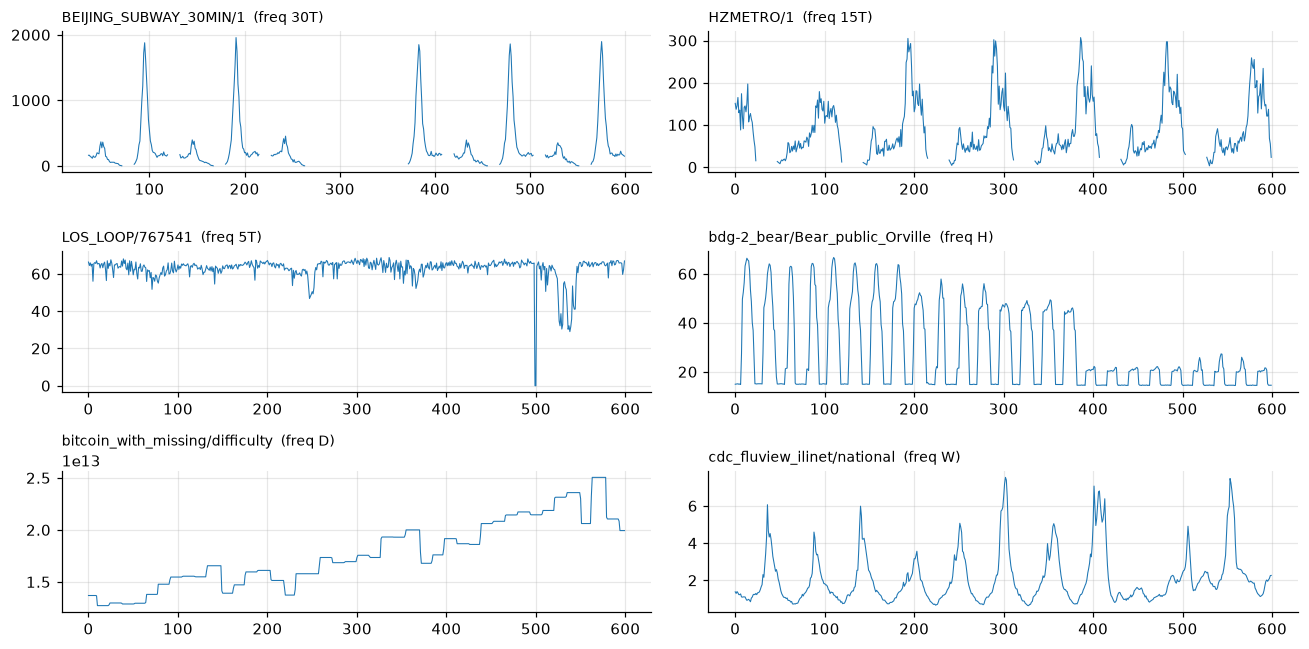

In [7]:
# По одному ряду каждой из шести частот
freqs = train_set["freq"]
picked = {}
for i, f in enumerate(freqs):
    if f not in picked and values[i].shape[1] >= 300:
        picked[f] = i
    if len(picked) == 6:
        break

fig, axes = plt.subplots(3, 2, figsize=(12, 6))
for ax, (f, i) in zip(axes.flat, picked.items()):
    ax.plot(values[i][0][-600:], lw=0.7)
    ax.set_title(f"{train_set[i]['item_id']}  (freq {f})", fontsize=9, loc="left")
fig.tight_layout()

### 3.2. Смесь: как часто модель видит каждый источник

Источники очень разные по размеру. Если брать случайное окно из случайного ряда, крупные источники займут почти всё обучение. Если сначала выбирать источник равновероятно, маленький источник из 20 рядов будет повторяться в каждом батче.

В nanoTSFM это одна строчка: источник выбирается с весом $(\text{число рядов})^p$. $p = 0$ означает «каждый источник поровну», $p = 1$ означает «каждый ряд поровну».

In [8]:
print(inspect.getsource(Windows.__init__))

    def __init__(self, dataset, context: int, horizon: int, count: int, seed: int, power=0.0):
        """Draw a source with weight (its series count) ** power, then a series from it.

        Power 0 weights sources equally, 1 weights every series equally.
        """
        self.context, self.horizon, self.count, self.seed = context, horizon, count, seed
        sources = {}
        for source, values in zip(dataset["source"], arrays(dataset), strict=True):
            if values.shape[1] > horizon:
                sources.setdefault(source, []).append(values)
        self.sources = list(sources.values())
        if not self.sources or min(context, horizon, count) <= 0:
            raise ValueError("No series longer than the horizon, or an invalid window/count")
        weights = np.array([len(source) for source in self.sources], dtype=float) ** power
        self.weights = weights / weights.sum() if power else None



источников из одного ряда: 11, рядов в самом большом: 822


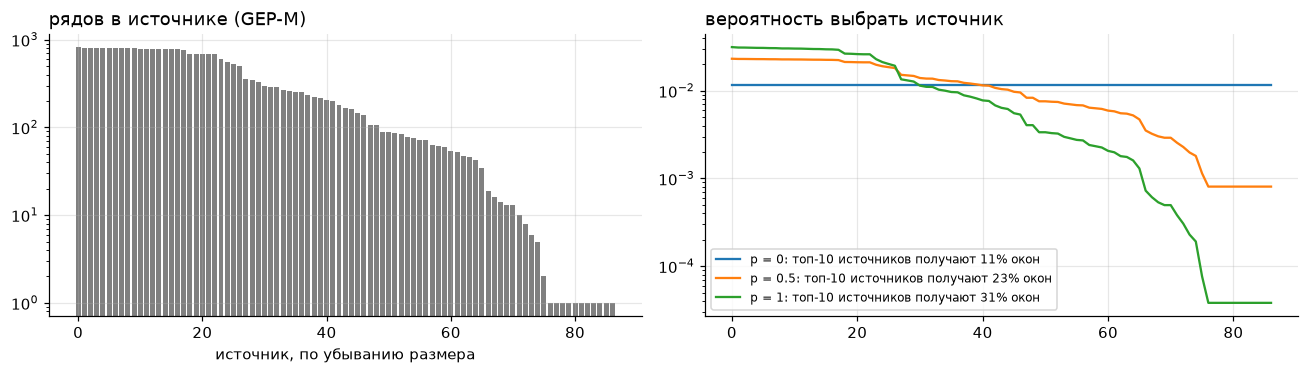

In [9]:
counts = np.array(sorted(sources.values(), reverse=True), dtype=float)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].bar(range(len(counts)), counts, color="0.5")
axes[0].set_yscale("log")
axes[0].set_title("рядов в источнике (GEP-M)", loc="left")
axes[0].set_xlabel("источник, по убыванию размера")
for p in (0, 0.5, 1):
    w = counts**p / (counts**p).sum()
    axes[1].plot(w, label=f"p = {p}: топ-10 источников получают {w[:10].sum():.0%} окон")
axes[1].set_yscale("log")
axes[1].set_title("вероятность выбрать источник", loc="left")
axes[1].legend(fontsize=8)
fig.tight_layout()
print(f"источников из одного ряда: {(counts == 1).sum()}, рядов в самом большом: {counts[0]:.0f}")

При $p = 0$ источник из одного ряда получает столько же окон, сколько источник из 800 рядов: модель видит этот один ряд в сотни раз чаще, чем любой ряд большого источника, и может его просто запомнить.

Что это даёт на GIFT-Eval (относительный CRPS, меньше лучше):

| Смесь | GIFT-Eval | Откуда |
|---|---|---|
| $p = 0$, каждый источник поровну (бейзлайн) | 0.670 ± 0.007 | рекорд nanoTSFM, 3 seed |
| $p = 0.5$ | 0.657 ± 0.005 | абляция в том же рекорде, 3 seed |
| $p = 1$, каждый ряд поровну | 0.632 ± 0.005 | рекорд nanoTSFM, 3 seed |

Авторы рекорда сначала выбрали $p = 0.5$ по пилоту на одном seed (0.644), но на трёх seed $p = 1$ оказался лучше на каждом. Это самый большой шаг между соседними рекордами nanoTSFM, и он получен без единого изменения в модели. Мы обучаем обе крайние модели в фоне и в разделе 7 проверим это сами.

В Simons смесь устроена сложнее: бюджет делится поровну сначала между доменами, потом между источниками внутри домена, и каждый источник ограничен шестью эпохами (UniMax). У самой большой модели ряды дополнительно кластеризуются по форме, и слишком частые формы прореживаются.

### 3.3. Синтетика

Реальных данных мало, и каждый реальный ряд может оказаться в чьём-то тесте. Синтетику можно генерировать бесконечно и без утечки. Почти все современные модели учатся на смеси реальных и синтетических рядов.

Классический генератор **KernelSynth** придумали авторы Chronos: случайно выбираем несколько ядер гауссовского процесса из банка (периодические с разными периодами, гладкие, шум, линейный тренд), складываем или перемножаем их и сэмплируем ряд из получившегося процесса. Он помещается в 20 строк:

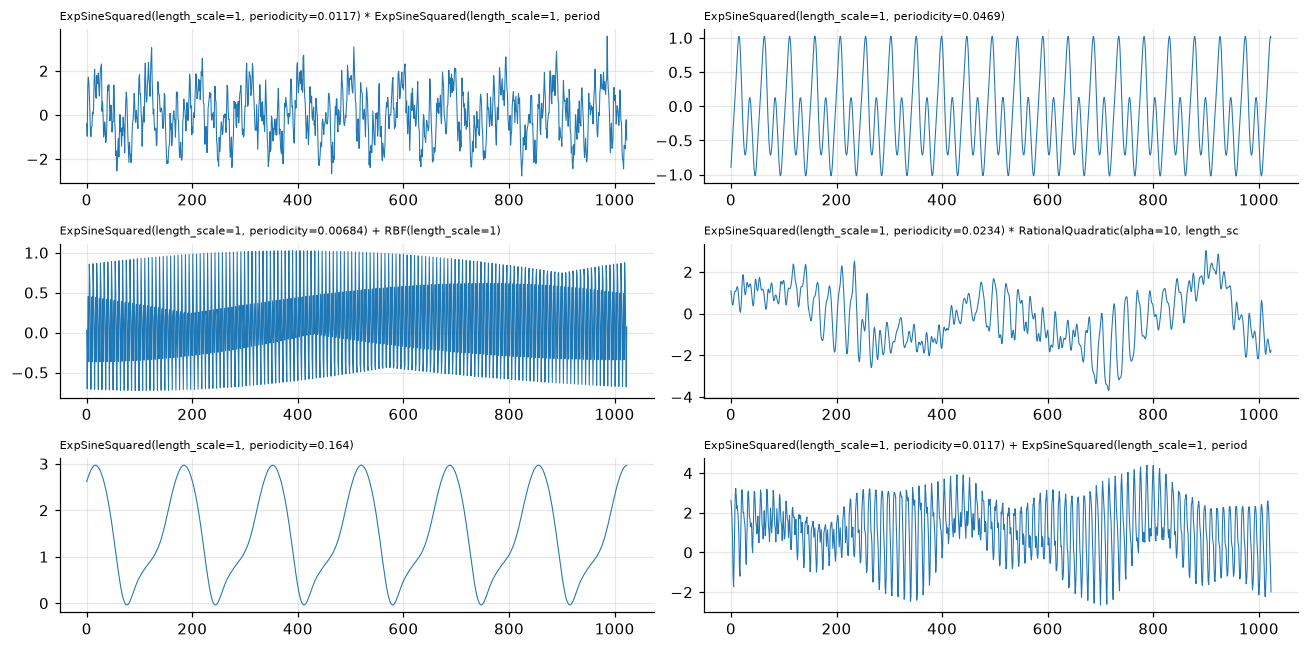

In [10]:
from sklearn.gaussian_process.kernels import (
    RBF,
    ConstantKernel,
    DotProduct,
    ExpSineSquared,
    RationalQuadratic,
    WhiteKernel,
)

LENGTH = 1024
BANK = (
    [ExpSineSquared(periodicity=p / LENGTH) for p in (7, 12, 24, 48, 96, 168, 336, 365)]
    + [RBF(length_scale=s) for s in (0.1, 1, 10)]
    + [RationalQuadratic(alpha=a) for a in (0.1, 1, 10)]
    + [WhiteKernel(noise_level=n) for n in (0.1, 1)]
    + [DotProduct(sigma_0=0.0), ConstantKernel()]
)


def kernel_synth(rng, length=LENGTH, max_kernels=5):
    chosen = rng.choice(len(BANK), size=rng.integers(1, max_kernels + 1))
    kernel = BANK[chosen[0]]
    for i in chosen[1:]:
        kernel = kernel + BANK[i] if rng.random() < 0.5 else kernel * BANK[i]
    x = np.linspace(0, 1, length)[:, None]
    covariance = kernel(x)
    for jitter in (1e-6, 1e-4, 1e-2):  # сумма и произведение ядер бывают почти вырожденными
        try:
            factor = np.linalg.cholesky(covariance + jitter * np.eye(length))
            break
        except np.linalg.LinAlgError:
            continue
    return factor @ rng.standard_normal(length), kernel


rng = np.random.default_rng(3)
fig, axes = plt.subplots(3, 2, figsize=(12, 6))
for ax in axes.flat:
    series, kernel = kernel_synth(rng)
    ax.plot(series, lw=0.7)
    ax.set_title(str(kernel)[:90], fontsize=7, loc="left")
fig.tight_layout()

Simons пошёл гораздо дальше: 18 семейств генераторов, от SARIMA и стохастических дифференциальных уравнений до прерывистого спроса, календарных профилей, эпидемических и гидрологических моделей. Первый этап обучения Simons идёт **только на синтетике**, реальные данные появляются на третьем этапе.

Посмотрим на часть семейств (тяжёлые механистические симуляторы пропускаем):

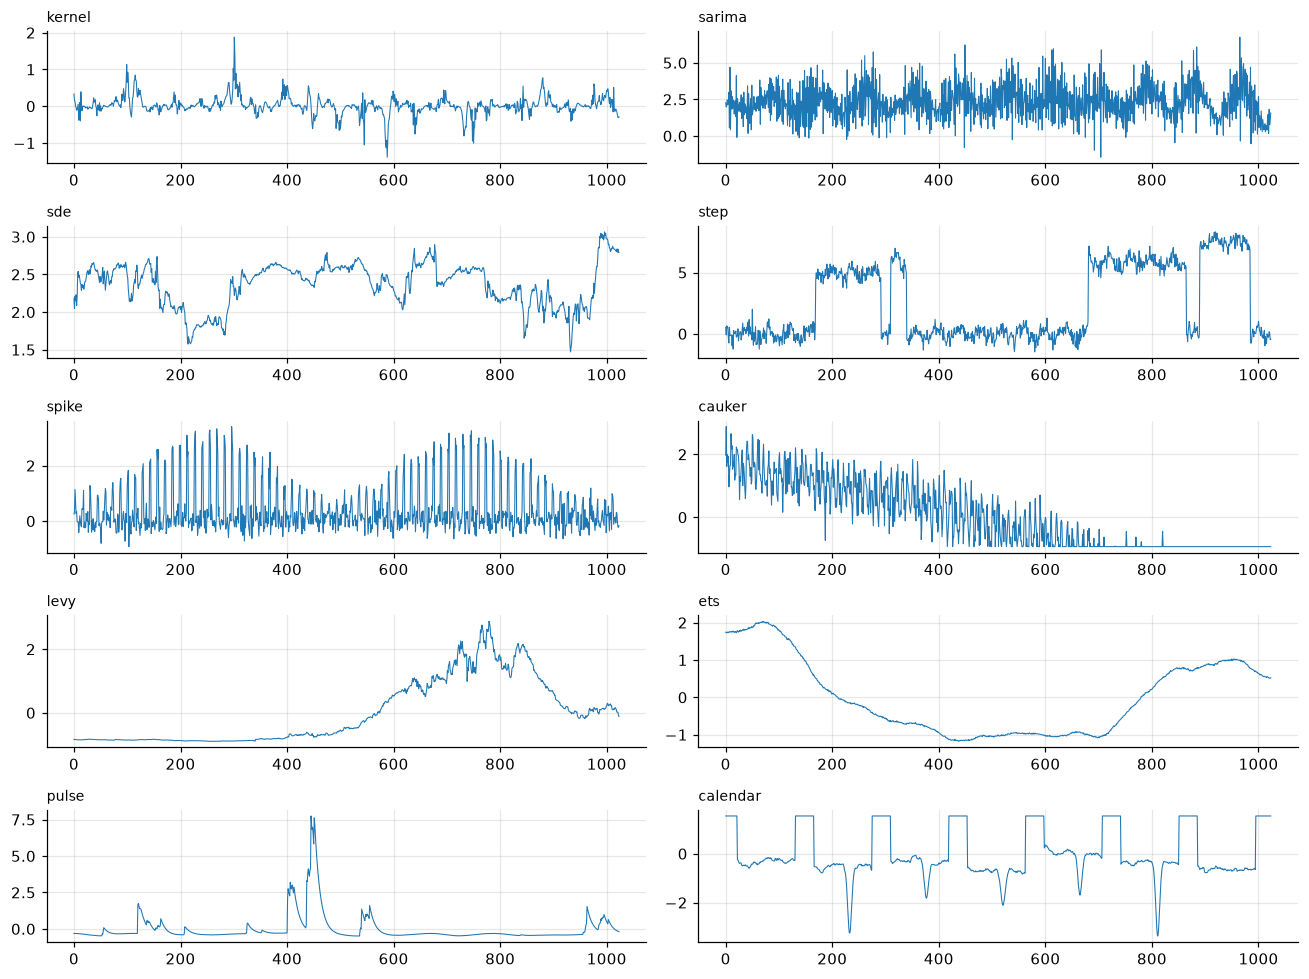

In [11]:
from simons.synth.base import family_makers

FAMILIES = [
    "kernel",
    "sarima",
    "sde",
    "step",
    "spike",
    "cauker",
    "levy",
    "ets",
    "pulse",
    "calendar",
]
makers = family_makers(FAMILIES)
gen = torch.Generator().manual_seed(0)

fig, axes = plt.subplots(5, 2, figsize=(12, 9))
for ax, family in zip(axes.flat, FAMILIES):
    series = makers[family](gen, 1, 1024, "cpu")[0].numpy()
    ax.plot(series, lw=0.7)
    ax.set_title(family, fontsize=9, loc="left")
fig.tight_layout()

Сколько даёт синтетика, по цифрам из статей:

- **Tabby**: без генератора CauKerV2 (ряды из случайных структурных причинных моделей) MASE на GIFT-Eval хуже на 2.3%: 0.7536 против 0.7368;
- **Simons**: авторы пишут, что около трёх четвертей выигрыша первой кампании дали данные и то, как ряд подаётся в модель, а изменения backbone дали мало. Абляций по отдельным семействам они не публикуют;
- **nanoTSFM**: в пилоте больше шагов и больше параметров на одном и том же реальном корпусе ухудшили GIFT-Eval (0.666 → 0.702 при 40 тыс. шагов), а разнообразие данных и смесь улучшили. Те же 40 тыс. шагов на GEP-L, где рядов в 15 раз больше, дали рекорд 0.561: больше шагов полезно только вместе с большим разнообразием данных. Модель быстро выучивает обучающий корпус, синтетика и смесь борются именно с этим.

### 3.4. Утечка

Zero-shot оценка имеет смысл, только если тестовых рядов не было в обучении. Проверить это сложнее, чем кажется:

- GIFT-Eval Pretrain и тест GIFT-Eval не делят ни одного ряда, но один и тот же ряд может лежать в двух источниках под разными именами. Документация nanoTSFM признаёт это про собственное разбиение по хешу имени: родственные датасеты PEMS оно различить не может;
- в статье про PatchTST-FM один из корпусов (TSMixup из Chronos) пересекается с 23 задачами GIFT-Eval. Модель на нём лучше по точечной оценке, но zero-shot её называть нельзя;
- Tabby дообучен (prompt tuning) на train-части задач GIFT-Eval, и в лидерборде он стоит в категории fine-tuned. В разделе 7 мы берём **Tabby-Pretrain**, предобученный backbone без этого шага. Но и его авторы сдали в категорию pretrained, а не zero-shot: по правилам GIFT-Eval это значит, что в корпус предобучения могли войти train-части тестовых датасетов;
- у Simons 37% реальных наблюдений из 111 закрытых источников. Авторы пишут, что тест исключён, но проверить это снаружи нельзя.

## 4. Как ряд попадает в модель

### 4.1. Масштаб: каузальная нормализация и asinh

Требование 3: модель не должна видеть абсолютных величин. Обычное решение (RevIN, instance normalization) вычитает среднее окна и делит на стандартное отклонение окна. Но при обучении на предсказание следующего патча (раздел 6) статистики всего окна подглядывают в будущее: в среднее окна входят те самые значения, которые мы предсказываем. У моделей, которые прогнозируют горизонт после контекста (Chronos-2, Tabby), этой проблемы нет: статистики считаются по видимой истории, а таргеты лежат вне её.

Поэтому nanoTSFM считает **каузальные** среднее и стандартное отклонение: для патча $i$ только по наблюдениям до конца этого патча (формула Уэлфорда на кумулятивных суммах). Так сделано в Toto, на котором основан nanoTSFM. Первая версия TimesFM берёт статистики первого патча: это тоже каузально, но после сдвига уровня они устаревают. На прогнозе каузальные статистики совпадают с обычными: пустые патчи горизонта их не меняют, и весь горизонт нормируется по последним 1024 наблюдениям. Затем значения сжимаются через $\operatorname{asinh}$: около нуля это почти тождественное преобразование, на больших значениях оно растёт как логарифм. Выбросы и тяжёлые хвосты перестают доминировать в потере.

In [12]:
from nanotsfm.model import causal_scale

print(inspect.getsource(causal_scale))

def causal_scale(values: torch.Tensor, patch: int):
    observed = torch.isfinite(values)
    x = torch.where(observed, values, 0).double()
    count = observed.cumsum(-1).clamp_min(1)
    loc = x.cumsum(-1) / count
    previous = F.pad(loc[..., :-1], (1, 0))
    # Welford update: sum of (x - old mean) * (x - new mean) over observed values.
    m2 = ((x - previous) * (x - loc) * observed).cumsum(-1)
    std = (m2 / (count - 1).clamp_min(1)).clamp_min(MIN_SCALE**2).sqrt()
    end = slice(patch - 1, None, patch)
    return loc[..., end], std[..., end]



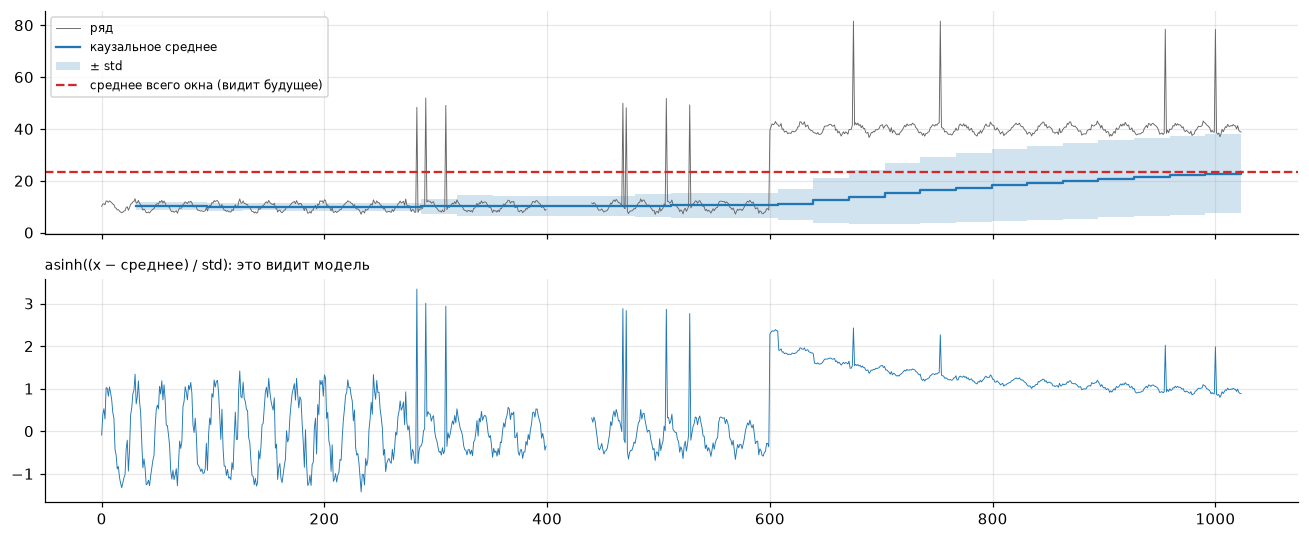

In [13]:
rng = np.random.default_rng(1)
t = np.arange(1024)
x = 10 + 2 * np.sin(2 * np.pi * t / 24) + rng.normal(0, 0.5, len(t))
x[600:] += 30  # сдвиг уровня
x[rng.random(len(t)) < 0.01] += 40  # выбросы
x[400:440] = np.nan  # пропуск

PATCH = 32
loc, scale = (s[0].numpy() for s in causal_scale(torch.tensor(x)[None], PATCH))
patch_end = np.arange(PATCH - 1, len(t), PATCH)
scaled = np.arcsinh((x - np.repeat(loc, PATCH)) / np.repeat(scale, PATCH))

fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].plot(t, x, lw=0.6, color="0.4", label="ряд")
axes[0].step(patch_end, loc, where="post", label="каузальное среднее")
axes[0].fill_between(patch_end, loc - scale, loc + scale, step="post", alpha=0.2, label="± std")
axes[0].axhline(np.nanmean(x), ls="--", color="C3", label="среднее всего окна (видит будущее)")
axes[0].legend(fontsize=8, loc="upper left")
axes[1].plot(t, scaled, lw=0.6)
axes[1].set_title("asinh((x − среднее) / std): это видит модель", loc="left", fontsize=9)
fig.tight_layout()

Заметьте: после сдвига уровня каузальная статистика долго «помнит» старый уровень, потому что nanoTSFM считает её по всей истории. Simons считает её в скользящем окне из последних 8192 наблюдений, а Tabby нормирует по видимой истории с учётом маски.

### 4.2. Патч и маска наблюдений

Требование 1: единица входа не наблюдение, а патч. В nanoTSFM патч из 32 значений после нормализации склеивается с 32 флагами «наблюдено / пропуск», получается токен из 64 чисел. Пропуск внутри патча модель видит явно, а не как ноль.

токены: (1, 1, 32, 64) = [batch, каналы, патчи, 32 значения + 32 флага]


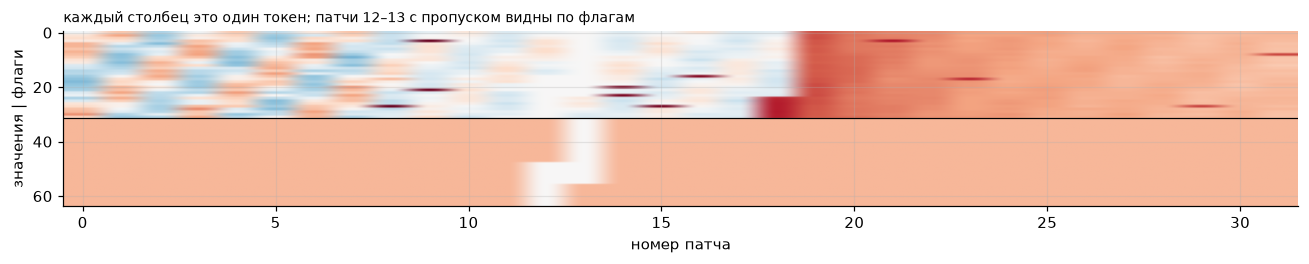

In [14]:
values_t = torch.tensor(x, dtype=torch.float32)[None, None]  # [B=1, V=1, T]
observed = torch.isfinite(values_t)
clean = torch.where(observed, torch.tensor(scaled, dtype=torch.float32)[None, None], 0)
tokens = torch.cat(
    [clean.unflatten(-1, (-1, PATCH)), observed.float().unflatten(-1, (-1, PATCH))], dim=-1
)
print("токены:", tuple(tokens.shape), "= [batch, каналы, патчи, 32 значения + 32 флага]")

plt.figure(figsize=(12, 2.5))
plt.imshow(tokens[0, 0].T, aspect="auto", cmap="RdBu_r", vmin=-3, vmax=3)
plt.axhline(31.5, color="k", lw=0.8)
plt.xlabel("номер патча")
plt.ylabel("значения | флаги")
plt.title(
    "каждый столбец это один токен; патчи 12–13 с пропуском видны по флагам", loc="left", fontsize=9
)
plt.tight_layout()

Длина патча в моделях разная: 32 у nanoTSFM и Simons, 16 у Tabby. Короткий патч точнее на коротких рядах, длинный дешевле: при одинаковом числе токенов контекст в наблюдениях вдвое длиннее.

### 4.3. Позиция: период как часть позиционного кодирования (Simons)

nanoTSFM кодирует позицию патча обычным RoPE: векторы query и key поворачиваются на угол, пропорциональный позиции, и скалярное произведение начинает зависеть от расстояния между патчами. Simons добавил к нему необычную деталь: перед прогнозом он **ищет в истории доминирующие периоды** (периодограмма, пик должен пройти тест Фишера и быть в 5 раз выше локального фона) и записывает фазу $2\pi \cdot \operatorname{frac}(t / P)$ в 4 самые медленные пары RoPE. Сезонность становится явной частью позиции, и частота ряда модели не нужна. Попробуем детектор на реальных рядах:

In [15]:
from simons import SimonsConfig
from simons.periodicity import detect_periods

cfg = SimonsConfig()
for f in ["H", "D", "15T", "W"]:
    i = next((i for i, fr in enumerate(freqs) if fr == f and values[i].shape[1] >= 2048), None)
    if i is None:
        continue
    history = torch.tensor(values[i][:1, -2048:])
    periods = detect_periods(
        history, 2048, cfg.period_slots, cfg.period_alpha, cfg.period_local, cfg.patch_length
    )
    print(f"{train_set[i]['item_id']:>40} (freq {f:>3}): периоды {periods[0].tolist()}")

          bdg-2_bear/Bear_public_Orville (freq   H): периоды [24.0, 170.0, 0.0, 0.0]
         bitcoin_with_missing/difficulty (freq   D): периоды [467.0, 0.0, 0.0, 0.0]
                               HZMETRO/1 (freq 15T): периоды [96.0, 48.0, 19.0, 51.0]
project_tycho/CA_CALIFORNIA_STATE_MEASLES_CASES (freq   W): периоды [52.0, 48.0, 57.0, 26.0]


## 5. Архитектура

Вся модель nanoTSFM занимает 100 строк. Сначала посмотрим на схему целиком: слева путь ряда от наблюдений до квантилей, справа устройство одного блока и то, на какие токены смотрит внимание.

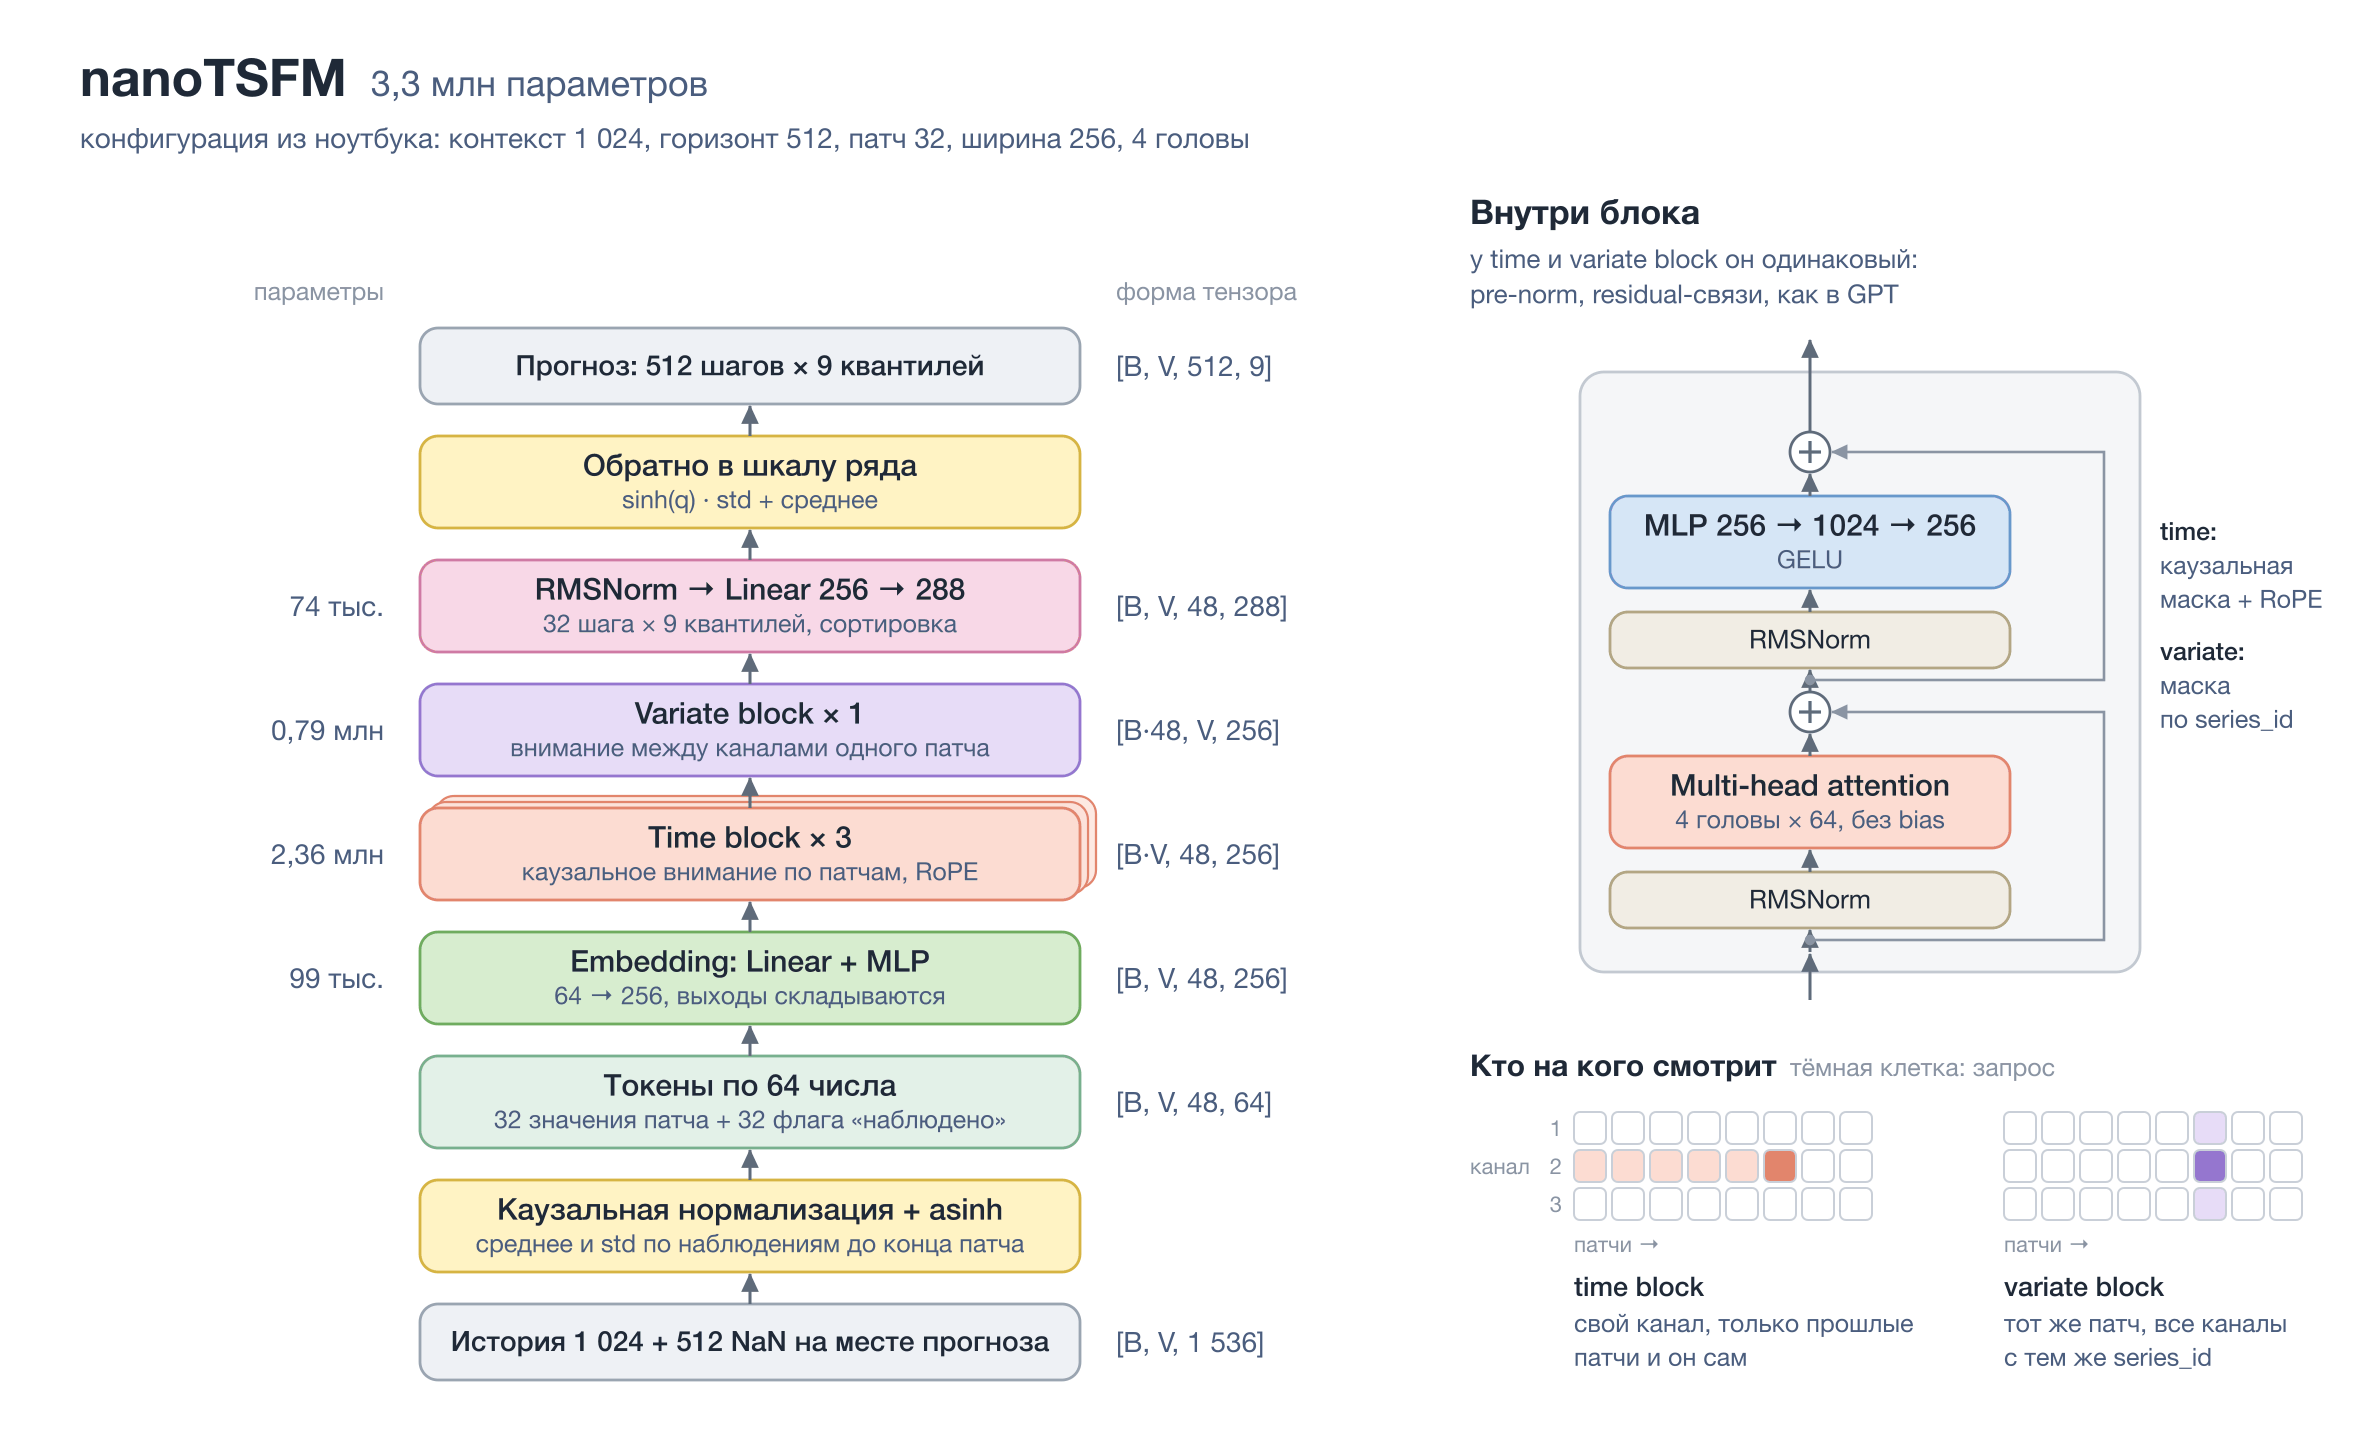

Теперь пройдём по модели тензором и посмотрим на размерности на каждом шаге.

In [16]:
from nanotsfm.model import ModelConfig, NanoTSFM

config = ModelConfig(**BASELINE["model"])
model = NanoTSFM(config)
print(f"всего параметров: {sum(p.numel() for p in model.parameters()):,}")
for name, module in model.named_children():
    print(f"  {name:>14}: {sum(p.numel() for p in module.parameters()):>9,}")

всего параметров: 3,326,240
           embed:    16,640
       embed_mlp:    82,432
     time_blocks: 2,364,672
   variate_block:   788,224
            norm:       256
            head:    74,016


In [17]:
print(inspect.getsource(NanoTSFM.next_patch))

    def next_patch(self, values: torch.Tensor, series_ids: torch.Tensor):
        """Predict the next patch from [B,V,T] values; equal IDs share variate attention."""
        batch, variates, length = values.shape
        patch = self.config.patch_length
        if length % patch:
            raise ValueError("Sequence length must divide into patches")
        patches = length // patch
        loc, scale = causal_scale(values, patch)
        observed = torch.isfinite(values)
        # Zero-fill before arithmetic so NaN never reaches the gradient.
        clean = torch.where(observed, values, 0).double()
        scaled = (clean - loc.repeat_interleave(patch, -1)) / scale.repeat_interleave(patch, -1)
        scaled = torch.where(observed, scaled, 0).asinh().float()
        tokens = torch.cat(
            [scaled.unflatten(-1, (patches, patch)), observed.float().unflatten(-1, (-1, patch))],
            dim=-1,
        )
        x = self.embed(tokens) + self.embed_mlp(tokens)

        x = 

In [18]:
shapes = []
hooks = [
    model.embed.register_forward_hook(
        lambda m, i, o: shapes.append(("embed: токен → вектор", o.shape))
    ),
    model.time_blocks[0].register_forward_hook(
        lambda m, i, o: shapes.append(("time block: внимание по патчам одного канала", o.shape))
    ),
    model.variate_block.register_forward_hook(
        lambda m, i, o: shapes.append(("variate block: внимание по каналам одного патча", o.shape))
    ),
    model.head.register_forward_hook(
        lambda m, i, o: shapes.append(("head: 32 шага × 9 квантилей", o.shape))
    ),
]
history = torch.randn(2, 3, config.context_length)  # 2 примера по 3 канала
series_ids = torch.tensor([[0, 0, 0], [0, 1, 2]])  # 1-й: один 3-мерный ряд, 2-й: три разных ряда
with torch.no_grad():
    out = model(history, series_ids)
for h in hooks:
    h.remove()
for what, shape in shapes:
    print(f"{what:<50} {tuple(shape)}")
print(f"{'прогноз [B, V, H, 9]':<50} {tuple(out.shape)}")

embed: токен → вектор                              (2, 3, 48, 256)
time block: внимание по патчам одного канала       (6, 48, 256)
variate block: внимание по каналам одного патча    (96, 3, 256)
head: 32 шага × 9 квантилей                        (2, 3, 48, 288)
прогноз [B, V, H, 9]                               (2, 3, 512, 9)


Что здесь стоит заметить:

- **Требование 2, независимость от каналов**: time blocks обрабатывают каждый канал отдельно (`[B·V, патчи, ширина]`), causal attention с RoPE. Каналы взаимодействуют только в одном variate block, где внимание идёт между каналами одного и того же патча, и только между каналами с одинаковым `series_ids`. Поэтому три независимых ряда можно положить в один пример, и они не будут смешиваться;
- **Требование 4, горизонт**: позиция $i$ предсказывает патч $i+1$. Чтобы получить 512 шагов за один проход, в конец истории дописываются 16 пустых патчей (`NaN`), и модель предсказывает их все сразу. Из 48 выходов прогнозом служат позиции 31–46 (считая с нуля): последний патч истории предсказывает первый патч будущего, а выход последнего пустого патча не нужен. Горизонт длиннее 512 закрывается повторными проходами по медиане;
- **квантильная голова**: линейный слой выдаёт $32 \times 9$ чисел на позицию, затем они сортируются, чтобы квантили не пересекались. В Tabby монотонность заложена в саму выходную голову: базовый уровень плюс кумулятивные softplus-приращения, 99 уровней.

Как то же самое устроено в больших моделях. Красной рамкой выделено то, чем Simons и Tabby отличаются от nanoTSFM:

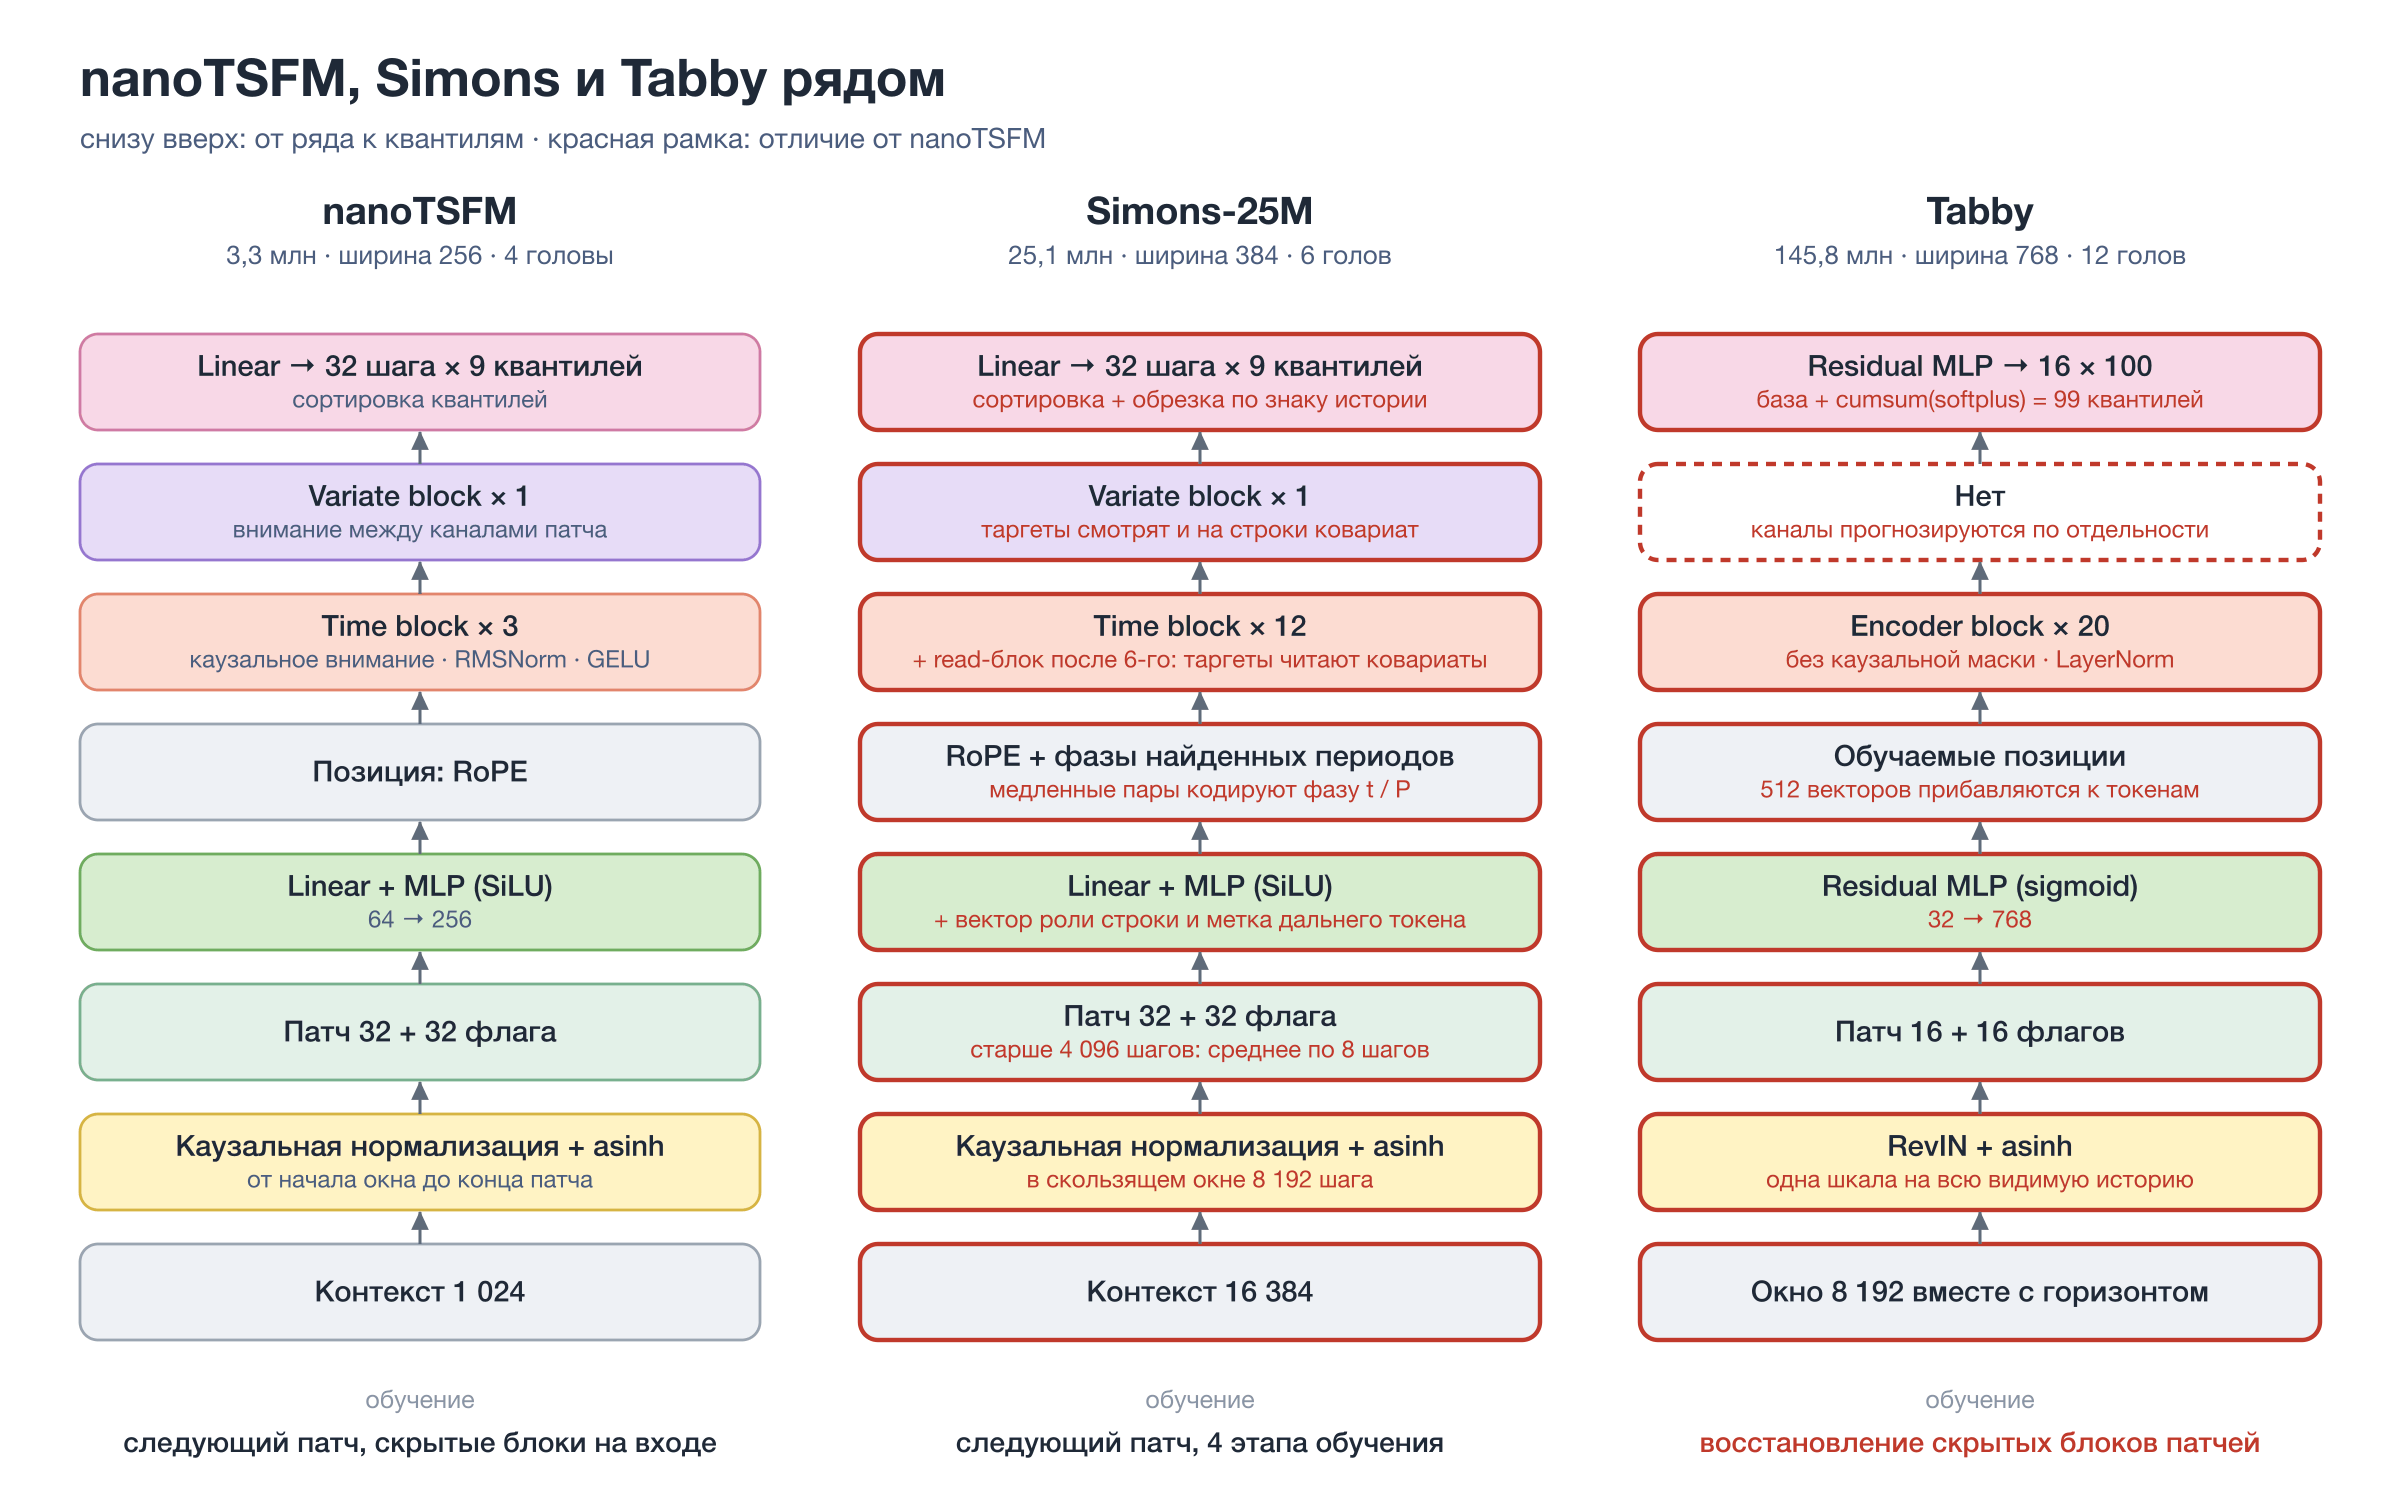

Сам блок трансформера у nanoTSFM и Simons одинаковый. Насколько вообще важен выбор backbone, проверили в [статье](https://arxiv.org/abs/2602.06909) Revisiting the Generic Transformer (модель из неё выложена под именем PatchTST-FM, так она называется и в Darts): под одним протоколом обучения и на одних данных (GIFT-Eval, MASE / CRPS):

| Backbone | Параметров | MASE | CRPS |
|---|---|---|---|
| Transformer | 33M | 0.731 | 0.509 |
| MLP-Mixer | 30M | 0.745 | 0.518 |
| Bi-Mamba2 | 37M | 0.755 | 0.518 |
| CNN-ResNet | 30M | 0.791 | 0.555 |

Трансформер лучше, но разница между первыми тремя меньше, чем разница от смеси данных в nanoTSFM.

## 6. Обучение

### 6.1. Цель: следующий патч, часть патчей скрыта

Из каждого окна длиной $1024 + 512$ модель учится предсказывать **каждый** следующий патч по предыдущим: позиция 1 предсказывает патч 2, позиция 2 патч 3 и так далее. Одно окно даёт десятки обучающих примеров с разной длиной истории, и горизонт обучения ни к чему не привязан.

Чтобы модель училась прогнозировать через пропуски и на несколько патчей вперёд, часть патчей на входе скрывается: подряд идущими блоками до 8 патчей, всего до 40% ряда.

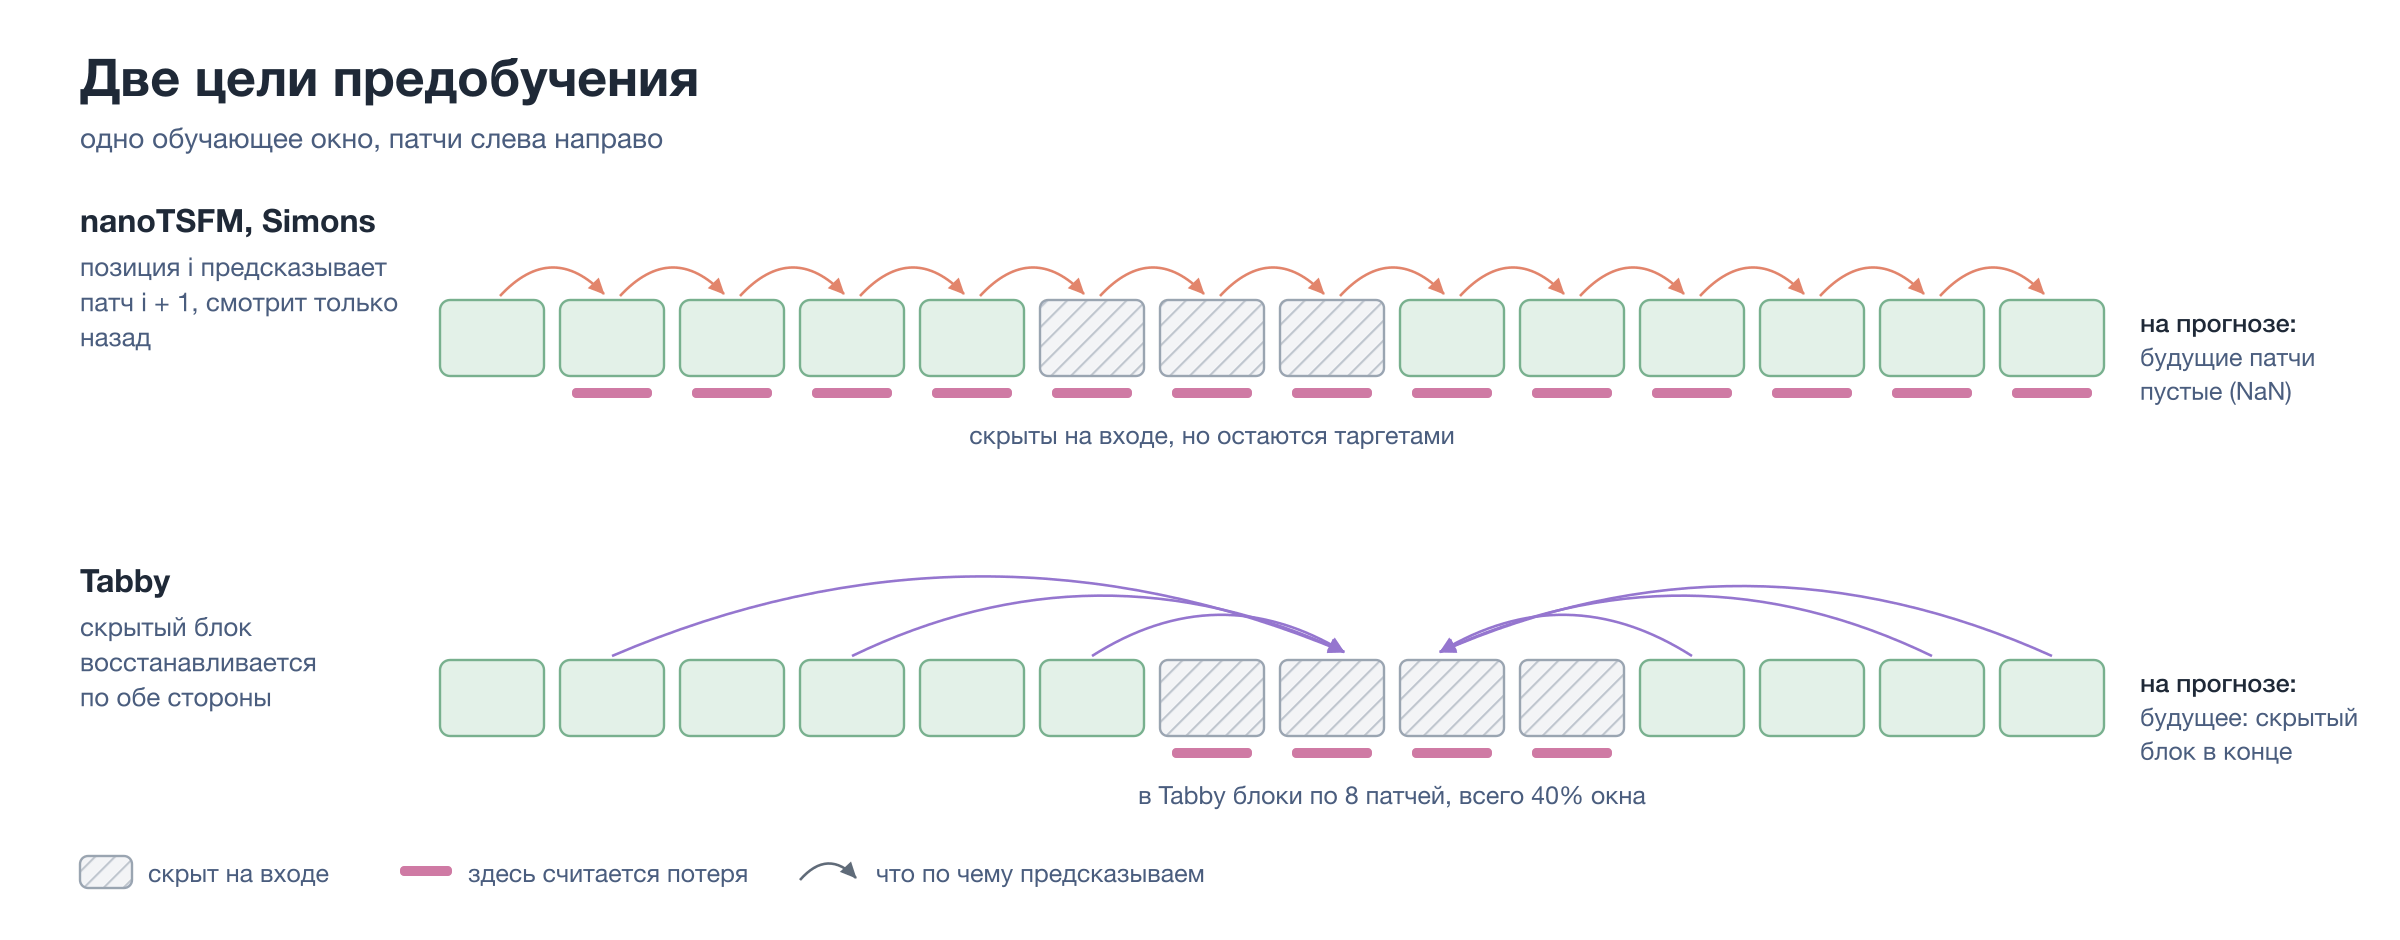

У Tabby цель другая: скрытые блоки он восстанавливает по патчам с обеих сторон, а при прогнозе будущее для него просто скрытый блок в конце окна. Поэтому Tabby устроен как энкодер без каузальной маски. Иногда при обучении он скрывает и самый конец окна, до двух патчей: так обучение прямо похоже на прогноз.

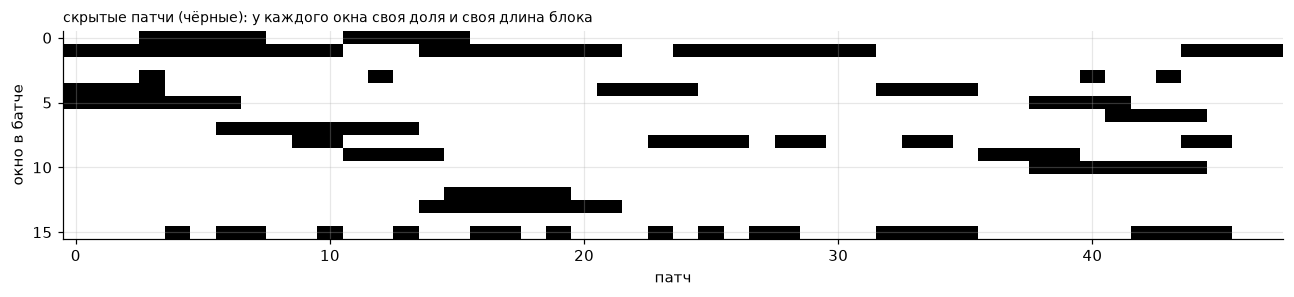

In [19]:
from nanotsfm.train import contiguous_patch_mask, learning_rate, pinball_loss

torch.manual_seed(0)
hidden = contiguous_patch_mask((16, 48), "cpu")
plt.figure(figsize=(12, 2.8))
plt.imshow(hidden, aspect="auto", cmap="Greys", interpolation="nearest")
plt.xlabel("патч")
plt.ylabel("окно в батче")
plt.title(
    "скрытые патчи (чёрные): у каждого окна своя доля и своя длина блока", loc="left", fontsize=9
)
plt.tight_layout()

Почему блоками, а не по одному патчу, хорошо видно в абляциях PatchTST-FM (GIFT-Eval):

| Маскирование | MASE | CRPS |
|---|---|---|
| отдельные патчи | 0.750 | 0.514 |
| блоки по 4 | 0.704 | 0.482 |
| блоки по 8 | 0.696 | 0.480 |

Это один из самых больших эффектов в статье, больше разницы между трансформером и Mamba. Доля скрытых патчей от 20% до 80% почти не влияет (0.696–0.703). Длина контекста тоже важна: 2048 → 8192 даёт 0.721 → 0.696.

### 6.2. Квантильная потеря

Модель выдаёт 9 квантилей, и каждый обучается своей квантильной (pinball) потерей:

$$\rho_q(y, \hat y) = \max\bigl(q\,(y - \hat y),\ (q - 1)(y - \hat y)\bigr).$$

При $q = 0.9$ недопрогноз штрафуется в 9 раз сильнее перепрогноза, и минимум достигается на 90%-м квантиле. Потеря считается в нормированной шкале (после asinh), поэтому все ряды вносят в неё сопоставимый вклад.

def pinball_loss(prediction: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
    observed = torch.isfinite(target)
    if prediction.shape != (*target.shape, len(QUANTILES)):
        raise ValueError("prediction and target shapes differ")
    if not observed.any():
        raise ValueError("Need at least one observed target")
    error = torch.where(observed, target, 0.0).unsqueeze(-1) - prediction
    quantiles = prediction.new_tensor(QUANTILES)
    loss = torch.maximum(quantiles * error, (quantiles - 1) * error)
    return (loss * observed.unsqueeze(-1)).sum() / (observed.sum() * len(QUANTILES))



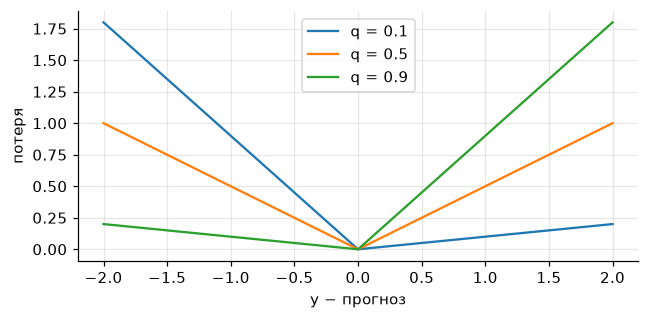

In [20]:
print(inspect.getsource(pinball_loss))

error = np.linspace(-2, 2, 201)
plt.figure(figsize=(6, 3))
for q in (0.1, 0.5, 0.9):
    plt.plot(error, np.maximum(q * error, (q - 1) * error), label=f"q = {q}")
plt.xlabel("y − прогноз")
plt.ylabel("потеря")
plt.legend()
plt.tight_layout()

### 6.3. Оптимизатор и расписание

nanoTSFM: AdamW, learning rate $10^{-3}$, 5% разогрев, косинусное затухание до 10%. Simons: NorMuon для матриц внутри блоков и AdamW для остального, расписание warmup-stable-decay (WSD: разогрев, долгое плато с постоянным learning rate, короткое затухание в конце), перенос learning rate между размерами модели (muP). NorMuon это вариант оптимизатора Muon: шаг для матрицы весов ортогонализуется, чтобы ни одно направление не забирало всё обновление. Tabby сравнил расписания на маленькой модели (40M, 110 тыс. шагов, GIFT-Eval):

| Расписание | MASE | CRPS |
|---|---|---|
| WSD-S | 0.7551 | 0.5165 |
| косинус | 0.7456 | 0.5112 |
| PCS (их вариант) | 0.7368 | 0.5038 |

WSD-S повторяет циклы «плато + затухание» несколько раз. PCS (progressive convergence schedule) делает так же, но каждое следующее плато идёт на вдвое меньшем learning rate. В конце каждого цикла получается дообученный до сходимости чекпойнт: его можно честно оценить и решить, менять ли смесь данных, не начиная обучение заново.

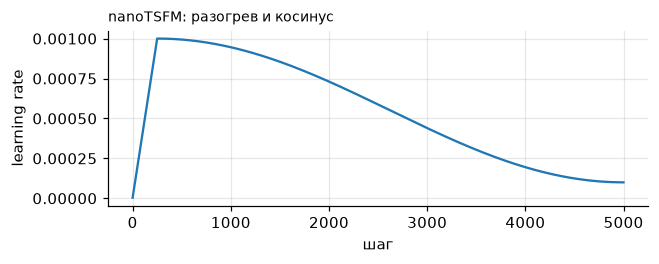

In [21]:
steps = np.arange(5000)
plt.figure(figsize=(6, 2.5))
plt.plot(steps, [learning_rate(s, 5000, 1e-3) for s in steps])
plt.xlabel("шаг")
plt.ylabel("learning rate")
plt.title("nanoTSFM: разогрев и косинус", loc="left", fontsize=9)
plt.tight_layout()

### 6.4. Бюджеты

| Модель | Обучение |
|---|---|
| nanoTSFM 3.3M | 5000 шагов, около 2 минут на A100 |
| Tabby-Small 40M | 8 GPU, 110 тыс. шагов |
| Simons-25M | 4 этапа, около 21 часа на одном GPU с 96 ГБ |
| Simons, вся разработка | около 2000 экспериментов, меньше $8000 на GPU, эксперименты ставили агенты (об этом во втором семинаре) |

### 6.5. Наши запуски

Вернёмся к фоновому обучению. Training loss считается на обучающих окнах, validation loss на отложенных рядах **тех же источников** (GEP-M validation).

In [22]:
progress()

   uniform: шаг 225/5000, loss 0.1842, 9.0 шагов/с, осталось около 8.9 мин
per-series: ещё не начался


   uniform: шаг 225/5000, loss 0.1842, 9.0 шагов/с, осталось около 8.9 мин
per-series: ещё не начался


   uniform: шаг 625/5000, loss 0.1656, 11.2 шагов/с, осталось около 6.5 мин
per-series: ещё не начался


   uniform: шаг 850/5000, loss 0.1665, 10.2 шагов/с, осталось около 6.8 мин
per-series: ещё не начался


   uniform: шаг 1275/5000, loss 0.1555, 11.1 шагов/с, осталось около 5.6 мин
per-series: ещё не начался


   uniform: шаг 1775/5000, loss 0.1448, 12.4 шагов/с, осталось около 4.3 мин
per-series: ещё не начался


   uniform: шаг 2200/5000, loss 0.1436, 12.7 шагов/с, осталось около 3.7 мин
per-series: ещё не начался


... (14 outputs left out)

   uniform: шаг 5000/5000, loss 0.1249, 14.7 шагов/с, осталось около 0.0 мин
per-series: шаг 4250/5000, loss 0.1481, 15.5 шагов/с, осталось около 0.8 мин


   uniform: шаг 5000/5000, loss 0.1249, 14.7 шагов/с, осталось около 0.0 мин
per-series: шаг 4525/5000, loss 0.1458, 14.8 шагов/с, осталось около 0.5 мин


   uniform: шаг 5000/5000, loss 0.1249, 14.7 шагов/с, осталось около 0.0 мин
per-series: шаг 4800/5000, loss 0.1453, 14.4 шагов/с, осталось около 0.2 мин


   uniform: шаг 5000/5000, loss 0.1249, 14.7 шагов/с, осталось около 0.0 мин
per-series: шаг 5000/5000, loss 0.1537, 14.1 шагов/с, осталось около 0.0 мин
обучение закончено
   uniform: 5000 шагов за 341 с, validation loss 0.1972
per-series: 5000 шагов за 356 с, validation loss 0.2129


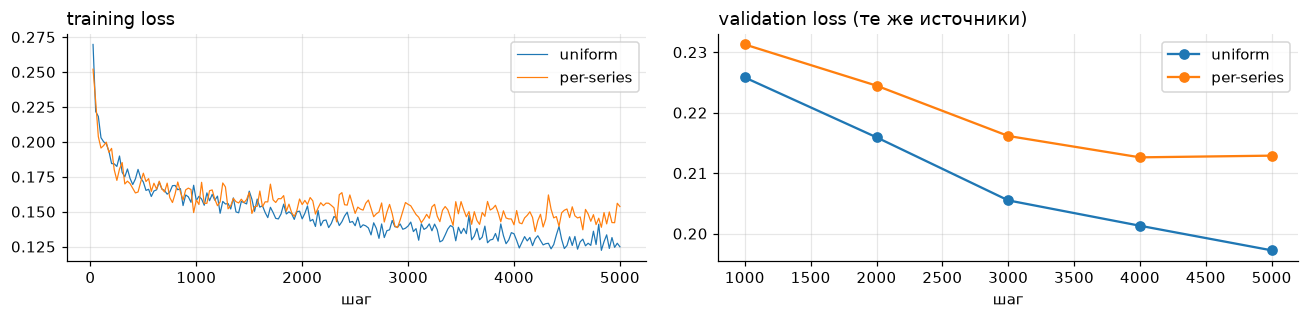

In [23]:
def wait_for_training():
    while trainer.poll() is None:
        progress()
        time.sleep(30)
    progress()
    assert trainer.returncode == 0, (RUNS / "train.log").read_text()[-2000:]


wait_for_training()

fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for name in EXPERIMENTS:
    rows = [json.loads(line) for line in (RUNS / name / "training.jsonl").read_text().splitlines()]
    train_rows = [r for r in rows if "loss" in r]
    val_rows = [r for r in rows if "validation_loss" in r]
    axes[0].plot(
        [r["step"] for r in train_rows], [r["loss"] for r in train_rows], lw=0.8, label=name
    )
    axes[1].plot(
        [r["step"] for r in val_rows], [r["validation_loss"] for r in val_rows], "o-", label=name
    )
    run = json.loads((RUNS / name / "run.json").read_text())
    print(
        f"{name:>10}: {run['steps']} шагов за {run['elapsed_seconds']:.0f} с, "
        f"validation loss {run['validation_loss']:.4f}"
    )
axes[0].set_title("training loss", loc="left")
axes[1].set_title("validation loss (те же источники)", loc="left")
for ax in axes:
    ax.set_xlabel("шаг")
    ax.legend()
fig.tight_layout()

Сравнивать две смеси по этим графикам нельзя. Training loss у них считается на разных окнах. Validation loss считается на одних и тех же отложенных окнах, но источники в них взяты поровну, как при обучении `uniform`. Это родное распределение одной из двух моделей, и метрика ей подыгрывает. Поэтому сравниваем на отдельной оценке, где состав задач и метрики не связаны ни с одной из смесей, к ней и переходим.

## 7. Сравнение: наши модели, Simons и Tabby

### 7.1. На знакомых источниках: GEP-Val

GEP-Val: 129 задач на отложенных рядах **тех же 70 источников**, на которых модели учились. Это диагностика, а не zero-shot: она показывает, насколько хорошо модель выучила обучающий корпус.

In [24]:
from nanotsfm.evaluation import evaluate_heldout

gep = {}
for name in EXPERIMENTS:
    out = RUNS / name / "gep-val.json"
    if not out.exists():
        evaluate_heldout(RUNS / name / "checkpoint.pt", "validation", out, DEVICE)
    gep[name] = json.loads(out.read_text())["summary"]
    print(
        f"{name:>10}: GEP-Val relative CRPS {gep[name]['geometric_relative_crps']:.4f}, "
        f"MASE {gep[name]['geometric_relative_mase']:.4f}"
    )

GEP-Val: relative CRPS 0.6234, relative MASE 0.8032 over 129 tasks
   uniform: GEP-Val relative CRPS 0.6234, MASE 0.8032


GEP-Val: relative CRPS 0.6129, relative MASE 0.7824 over 129 tasks
per-series: GEP-Val relative CRPS 0.6129, MASE 0.7824


### 7.2. На новых данных: мини-GIFT-Eval

Теперь возьмём пять датасетов из теста GIFT-Eval, которых не было в GEP-M и, по словам авторов, в обучении Simons. Tabby-Pretrain сдан в категорию pretrained: в его корпус могли входить train-части этих датасетов, но не тестовые окна. Протокол упрощённый: у каждого ряда прогнозируем последние $H$ наблюдений по истории до них (каждая модель берёт из неё столько, сколько вмещает её контекст: nanoTSFM 1024 наблюдения, Tabby до 8192 вместе с горизонтом, Simons-25M 16 384), горизонт и сезонность как в коротком горизонте GIFT-Eval. Цифры поэтому не совпадут с официальными, но сравнивать модели между собой можно.

Метрики считаем функциями из nanoTSFM, теми же, что в GEP-Val: CRPS и MASE по датасету, делённые на Seasonal Naive, и геометрическое среднее по датасетам.

In [25]:
from datasets import load_from_disk
from huggingface_hub import snapshot_download

# датасет: (горизонт, сезонность)
GIFT_TASKS = {
    "m4_hourly": (48, 24),
    "m4_weekly": (13, 1),
    "hospital": (12, 12),
    "covid_deaths": (30, 7),
    "car_parts_with_missing": (12, 12),
}
gift_root = Path(
    snapshot_download(
        "Salesforce/GiftEval",
        repo_type="dataset",
        revision="30841734ac5cfddbd0c3bad6d09d2b6b32becbb0",
        allow_patterns=[f"{name}/*" for name in GIFT_TASKS],
    )
)
gift = {}
for name, (horizon, season) in GIFT_TASKS.items():
    ds = load_from_disk(str(gift_root / name))
    series = [np.asarray(row, dtype=np.float32) for row in ds["target"]]
    # Нужна история хотя бы в 2 сезона и хотя бы одно наблюдение в горизонте
    kept = [
        s
        for s in series
        if s.ndim == 1
        and np.isfinite(s[:-horizon]).sum() > 2 * season
        and np.isfinite(s[-horizon:]).any()
    ]
    gift[name] = [(s[:-horizon], s[-horizon:]) for s in kept]
    print(
        f"{name:>24}: {len(kept):>5} из {len(series)} рядов, H = {horizon}, "
        f"медианная длина {np.median([len(s) for s in kept]):.0f}"
    )

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Fetching 15 files: 100%|██████████| 15/15 [00:00<00:00, 980.37it/s]

               m4_hourly:   414 из 414 рядов, H = 48, медианная длина 1008
               m4_weekly:   359 из 359 рядов, H = 13, медианная длина 947
                hospital:   767 из 767 рядов, H = 12, медианная длина 84
            covid_deaths:   266 из 266 рядов, H = 30, медианная длина 212
  car_parts_with_missing:  2509 из 2674 рядов, H = 12, медианная длина 51


In [26]:
from nanotsfm.evaluation import aggregate, forecast_many, metrics, seasonal_naive, summarize
from nanotsfm.model import load_checkpoint


def nanotsfm_forecaster(checkpoint):
    model, _ = load_checkpoint(checkpoint, DEVICE)

    def predict(histories, horizon):
        out = forecast_many(model, [h[None] for h in histories], horizon)
        return [o[0] for o in out]

    return predict


def evaluate(predict):
    # Строки в формате GEP-Val: метрики модели и Seasonal Naive по каждому датасету
    rows = []
    for name, (horizon, season) in GIFT_TASKS.items():
        histories = [h for h, _ in gift[name]]
        predictions = predict(histories, horizon)
        scored, reference = [], []
        for (h, y), p in zip(gift[name], predictions):
            scored.append(metrics(h, y, p, season))
            reference.append(metrics(h, y, seasonal_naive(h, horizon, season), season))
        rows.append(
            {
                "dataset": name,
                "term": "short",
                "metrics": aggregate(scored),
                "seasonal_naive": aggregate(reference),
            }
        )
    return rows


results, timings = {}, {}
for name in EXPERIMENTS:
    start = time.time()
    results[f"nanoTSFM {name}"] = evaluate(nanotsfm_forecaster(RUNS / name / "checkpoint.pt"))
    timings[f"nanoTSFM {name}"] = time.time() - start

In [27]:
from simons import Simons, forecast_series

simons = Simons.from_pretrained("abel-lab/Simons-25M", device=DEVICE)
print(f"Simons-25M: {sum(p.numel() for p in simons.parameters()) / 1e6:.1f}M параметров")

for views in (False, True):
    label = "Simons-25M" + (" + views" if views else "")
    start = time.time()
    results[label] = evaluate(
        lambda hs, horizon, views=views: forecast_series(simons, hs, horizon, views=views)
    )
    timings[label] = time.time() - start

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 881.06it/s]

Simons-25M: 25.1M параметров


`views` у Simons: прогноз строится четыре раза, для $x$, $-x$, $\sqrt{x}$ и $-\sqrt{x}$ (корни только для неотрицательных рядов), результаты переводятся обратно, и по каждому квантилю берётся среднее двух средних из четырёх значений, то есть медиана. Это аугментация во время инференса, которая стоит в 4 раза больше вычислений. Посмотрим, сколько она даёт.

Tabby-Pretrain берём через предиктор из репозитория Tabby, в формате GluonTS:

In [28]:
import pandas as pd
from tabby.predictor import PatchTSTFMPredictor

# fp16 даёт те же цифры, что fp32, до третьего знака, и считает в 4–5 раз быстрее
tabby_predictor = PatchTSTFMPredictor(
    checkpoint="paris-noah/Tabby-Pretrain",
    prediction_length=1,
    device=DEVICE,
    batch_size=64,
    precision="fp16" if DEVICE == "cuda" else "fp32",
)


def tabby(histories, horizon):
    tabby_predictor.prediction_length = horizon  # веса загружены один раз, горизонт меняем
    # Даты модели не нужны, но формат GluonTS требует start
    items = [{"start": pd.Period("2000-01-01", freq="D"), "target": h} for h in histories]
    return [f.forecast_array.T for f in tabby_predictor.predict(items)]  # [H, 9]


start = time.time()
results["Tabby-Pretrain"] = evaluate(tabby)
timings["Tabby-Pretrain"] = time.time() - start

/home/martin/cusem1/venv/lib/python3.12/site-packages/gluonts/json.py:102: UserWarning: Using `json`-module for json-handling. Consider installing one of `orjson`, `ujson` to speed up serialization and deserialization.
  warnings.warn(


Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Fetching 5 files: 100%|██████████| 5/5 [00:00<00:00, 1141.25it/s]

In [29]:
table = {}
for label, rows in results.items():
    summary = summarize(rows)
    per_dataset = {
        r["dataset"]: r["metrics"]["mean_weighted_sum_quantile_loss"]
        / r["seasonal_naive"]["mean_weighted_sum_quantile_loss"]
        for r in rows
    }
    table[label] = {
        "CRPS": summary["geometric_relative_crps"],
        "MASE": summary["geometric_relative_mase"],
        **per_dataset,
        "секунд": timings[label],
    }
pd.DataFrame(table).T.round(3)

,CRPS,MASE,m4_hourly,m4_weekly,hospital,covid_deaths,car_parts_with_missing,секунд
nanoTSFM uniform,0.680,1.132,0.780,0.781,0.858,0.371,0.750,0.739
nanoTSFM per-series,0.669,1.002,0.585,0.781,0.849,0.460,0.753,1.076
Simons-25M,0.439,0.679,0.421,0.584,0.675,0.168,0.584,1.693
Simons-25M + views,0.443,0.667,0.428,0.577,0.682,0.175,0.580,3.266
Tabby-Pretrain,0.570,0.832,0.502,0.735,0.734,0.344,0.644,43.915


Что стоит обсудить по этой таблице:

- помогла ли смесь `per-series` на новых данных так же, как в рекордах nanoTSFM? На всех датасетах или только в среднем? А на GEP-Val (раздел 7.1)?
- насколько Simons-25M и Tabby лучше нашей модели, обученной за несколько минут, и сколько это стоило в параметрах и данных;
- на официальном GIFT-Eval Simons-25M и Tabby-Pretrain почти рядом (CRPS 0.468 и 0.483, раздел 2). Совпадает ли это с нашей таблицей? Если нет, чему верить: 97 задачам или пяти? Что прячет геометрическое среднее?
- где модели хуже Seasonal Naive (значения больше 1, особенно по MASE) и почему;
- сколько дают `views` и стоят ли они почти вдвое большего времени (вычислений в 4 раза больше, но четыре варианта идут одним батчем).

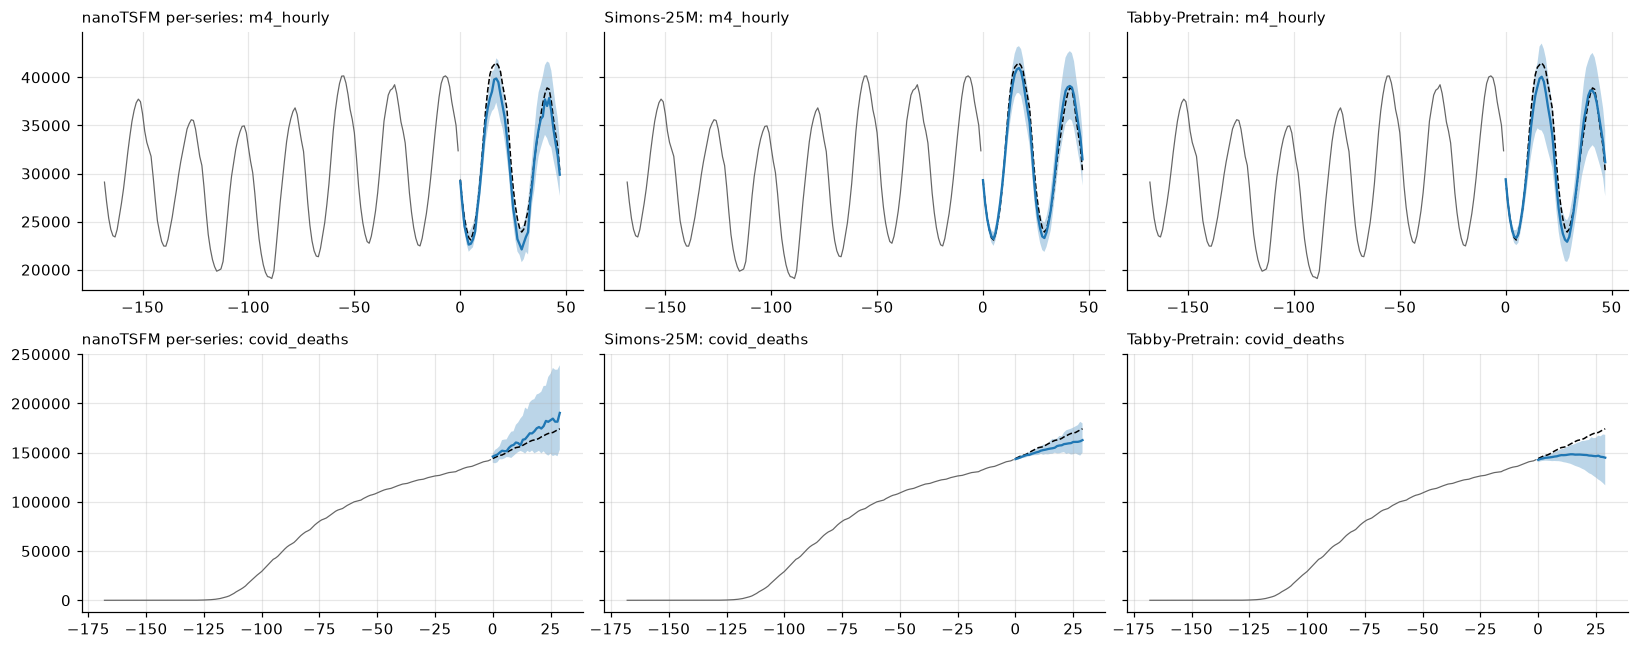

In [30]:
# Прогнозы всех моделей на двух рядах: простом часовом и накопленных смертях от COVID
covid_max = int(np.argmax([np.nanmax(h) for h, _ in gift["covid_deaths"]]))
examples = [("m4_hourly", 7), ("covid_deaths", covid_max)]
predictors = {
    "nanoTSFM per-series": nanotsfm_forecaster(RUNS / "per-series" / "checkpoint.pt"),
    # по умолчанию с views: это «Simons-25M + views» из таблицы выше
    "Simons-25M": lambda hs, h: forecast_series(simons, hs, h),
    "Tabby-Pretrain": tabby,
}
fig, axes = plt.subplots(len(examples), len(predictors), figsize=(15, 6), sharey="row")
for row, (name, index) in zip(axes, examples):
    horizon, season = GIFT_TASKS[name]
    history, target = gift[name][index]
    shown = min(len(history), 24 * 7)
    for ax, (label, predict) in zip(row, predictors.items()):
        q = predict([history], horizon)[0]
        ahead = np.arange(horizon)
        ax.plot(np.arange(-shown, 0), history[-shown:], color="0.4", lw=0.8)
        ax.plot(ahead, target, color="k", lw=1, ls="--")
        ax.fill_between(ahead, q[:, 0], q[:, -1], alpha=0.3)
        ax.plot(ahead, q[:, 4], lw=1.5)
        ax.set_title(f"{label}: {name}", loc="left", fontsize=10)
fig.tight_layout()

Нижний ряд накопленный: число смертей не может убывать. Модель об этом не знает, она видит только форму истории. Посмотрите, у какой модели медиана или нижний квантиль идут вниз и у какой интервал шире всего. Что из разделов 3–6 могло бы научить модель таким рядам?

## 8. Что открыто на самом деле

Мы прошли все компоненты foundation-модели. Последний вопрос: насколько всё это открыто на самом деле. Возьмём Tabby, который называет себя «complete and open recipe». В репозитории лежит рецепт обучения `recipes/pretrain/train_165k.sh`, а рядом с весами на Hugging Face файл `training_args.json`: параметры, с которыми веса были обучены на самом деле. Сравним:

In [31]:
from huggingface_hub import hf_hub_download

recorded = json.loads(
    Path(hf_hub_download("paris-noah/Tabby-Pretrain", "training_args.json")).read_text()
)
# Значения из recipes/pretrain/train_165k.sh (коммит 8675af0)
script = {
    "total_steps": 165000,
    "peak_lr": 2e-4,
    "min_lr": 1e-5,
    "num_cycles": 3,
    "decay_steps": 10000,
    "per_device_batch_size": 90,
    "grad_accum_steps": 4,
    "cauker_features": 9,
    "cauker_num_nodes": 9,
    "min_series_length": 96,
    "real_ratio": "$BLAST_RATIO",
    "cauker_V2_ratio": "$CAUKER_V2_RATIO",
    "gift_ratio": 0.3,
    "gift_data_root": None,
}
pd.DataFrame({"рецепт": script, "веса": {k: recorded.get(k) for k in script}}).astype(str)

,рецепт,веса
total_steps,165000,175000
peak_lr,0.0002,1e-05
min_lr,1e-05,1e-05
num_cycles,3,1
decay_steps,10000,20000
per_device_batch_size,90,200
grad_accum_steps,4,6
cauker_features,9,5
cauker_num_nodes,9,5
min_series_length,96,1024


Что видно из таблицы:

- learning rate, батч, число циклов расписания и параметры генератора CauKer в рецепте и в весах разные;
- доли BLAST и CauKer в рецепте не заданы: их нужно передать через переменные окружения. В комментарии к рецепту авторы пишут, что опубликованные материалы не позволяют восстановить финальную смесь;
- в docstring `train.py` сказано, что GIFT-Eval Pretrain при обучении Tabby-Pretrain не использовался. А в `training_args.json` весов стоит `gift_ratio = 0.3` и путь к GIFT-Eval Pretrain.

И наконец, просто запустим опубликованный рецепт. Данные не нужны: подставим пустые папки и доли смеси из `training_args.json`.

In [32]:
import urllib.request

BASE = (
    "https://raw.githubusercontent.com/huawei-noah/trustworthyAI/"
    "8675af0bc532c7f138158ded62e8cf303e9af655/TabbyTSFM/recipes/pretrain/"
)
recipe = Path("tabby_recipe")
(recipe / "recipes" / "pretrain").mkdir(parents=True, exist_ok=True)
for f in ("train.py", "train_165k.sh"):
    urllib.request.urlretrieve(BASE + f, recipe / "recipes" / "pretrain" / f)
for d in ("blast", "kernel_synth"):
    (recipe / d).mkdir(exist_ok=True)

env = dict(
    os.environ,
    PATH=f"{Path(sys.executable).parent}:{os.environ['PATH']}",  # torchrun
    BLAST_DATA_ROOT="blast",
    SYNTHETIC_ARROW_ROOT="kernel_synth",
    BLAST_RATIO=str(recorded["real_ratio"]),
    CAUKER_V2_RATIO=str(recorded["cauker_V2_ratio"]),
    CUDA_VISIBLE_DEVICES="0",
    NPROC_PER_NODE="1",
)
run = subprocess.run(
    ["bash", "recipes/pretrain/train_165k.sh", "out"],
    cwd=recipe,
    env=env,
    capture_output=True,
    text=True,
    timeout=600,
)
print("код возврата:", run.returncode)
errors = [line for line in (run.stdout + run.stderr).splitlines() if "ValueError" in line]
print(errors[-1] if errors else (run.stdout + run.stderr)[-2000:])

код возврата: 1
[rank0]: ValueError: --gift_data_root is required when --gift_ratio > 0.


Рецепт падает сразу, на проверке аргументов: он передаёт `--gift_ratio 0.3`, но не передаёт путь к данным GIFT-Eval Pretrain. Мы не утверждаем, что авторы что-то скрывают. Скорее всего, рецепт собирали из рабочих скриптов уже после обучения. Но «код открыт» и «результат воспроизводится» это разные утверждения, и проверить второе можно только запуском.

| | nanoTSFM | Simons | Tabby |
|---|---|---|---|
| Код обучения | да | да | да, но рецепт не запускается и расходится с весами |
| Данные | да, 730 МБ | этапы 1–2 синтетика; 37% реальных из закрытых источников | BLAST и синтетика открыты. Доли смеси есть только в `training_args.json` весов, и это смесь с GIFT-Eval Pretrain; смесь без него, которую описывает рецепт, не раскрыта. Генератор KernelSynth не приложен |
| Абляции | рекорды с 3 seed и пилот | нет, только «¾ выигрыша от данных» | да, таблицы в статье |
| Лицензия весов | обучаем сами | OpenMDW-1.1 | CC-BY-NC-4.0 |
| Воспроизвести целиком | да, 2 минуты на A100 | только этапы 1–2 | нет |

Полностью воспроизводимы пока только учебные модели вроде nanoTSFM и модели 2024 года (оригинальный Chronos, Moirai 1.x), у которых выложены и корпус, и скрипты. Поэтому nanoTSFM устроен как соревнование: любое изменение принимается, только если оно воспроизводится при переобучении на трёх seed.

## 9. Итоги

| вопрос | ответ |
|---|---|
| из чего состоит foundation-модель | данные и их смесь, синтетика, нормализация, патчи, архитектура, цель обучения, квантильная потеря и оценка |
| что важнее всего для качества | данные и то, как ряд подаётся в модель, а не backbone. Смесь «каждый ряд поровну» вместо «каждый источник поровну» улучшает GIFT-Eval с 0.670 до 0.632 без изменений в модели |
| зачем синтетика | её можно генерировать бесконечно и без утечки. Simons на первом этапе учится только на синтетике, у Tabby без генератора CauKerV2 MASE хуже на 2.3% |
| как модель не зависит от масштаба | каузальная нормализация по наблюдениям до конца патча и сжатие через asinh |
| как модель обходится без частоты и горизонта | частоту модель не получает, сезонность видит по самому ряду (Simons ещё и записывает найденный период в позиционное кодирование); позиция $i$ предсказывает патч $i+1$, для длинного горизонта в конец дописываются пустые патчи |
| как модель не смешивает независимые ряды | внимание между каналами есть только в variate block и только внутри одного ряда (`series_ids`) |
| почему патчи скрывают блоками | в абляциях PatchTST-FM блоки по 8 патчей дают MASE 0.696 против 0.750 у отдельных патчей. Это больше, чем разница между трансформером и Mamba |
| как честно сравнить две модели | на оценке, не связанной с обучением: свои задачи, свои метрики. Validation loss nanoTSFM берёт источники поровну, как смесь `uniform`, и подыгрывает ей. Zero-shot только если тестовых рядов не было в обучении |
| насколько наша модель хуже больших | на мини-GIFT-Eval CRPS 0.669 у nanoTSFM после нескольких минут обучения, 0.570 у Tabby-Pretrain и 0.439 у Simons-25M |
| что открыто на самом деле | полностью воспроизводимы учебные модели вроде nanoTSFM и модели 2024 года. Рецепт Tabby расходится с весами и падает при запуске |

**Во втором семинаре**: библиотеки, через которые эти модели используют на практике, и агенты: от агента, который выбирает модель для ряда, до агентов, которые сами собрали Simons за 2000 экспериментов.

Ссылки:
- nanoTSFM: [код](https://github.com/Abel-ai-lab/nanoTSFM), [данные](https://huggingface.co/datasets/abel-lab/nanoTSFM-pretrain), направления улучшений в `docs/directions.md`;
- Simons: [код](https://github.com/Abel-ai-lab/Simons), [веса](https://huggingface.co/abel-lab);
- Tabby: [статья](https://arxiv.org/abs/2609.13956), [код](https://github.com/huawei-noah/trustworthyAI/tree/master/TabbyTSFM), [веса](https://huggingface.co/paris-noah/Tabby-Pretrain);
- PatchTST-FM, абляции generic-трансформера: [статья](https://arxiv.org/abs/2602.06909);
- GIFT-Eval: [бенчмарк](https://github.com/SalesforceAIResearch/gift-eval).